# Kandy · CIFAKE baseline training and exploration

**Research question:** What fools an AI-image detector?

This **single notebook** contains the model definition, data preparation, training/resume code, visualizations, completed-run metrics, and the trained baseline weights. It does not need sibling Python scripts, a separate model download, or a results directory. Saved outputs can be read on GitHub.

**To use the trained model:** install the packages in Section 1, leave `MODE = "review"` in Section 2, and run the cells from top to bottom. Section 9 loads the included weights into `model`, ready for inference on CPU or GPU. The dataset is needed only for live image exploration, training, or evaluation.

The completed plain CNN selected **epoch 19** by validation loss: **94.54% validation accuracy** and **94.29% official test accuracy**. Review mode reads the existing results and does not retrain or repeat test evaluation. To train a separate experiment, choose a new `RUN_NAME` and set `MODE = "train"`. Every completed epoch is checkpointed locally.

## 1. Environment and notebook implementation

Use Python 3.12 and select that environment as the notebook kernel in VS Code or Jupyter. If dependencies are missing, set `INSTALL_DEPENDENCIES = True` in the next cell, run it once, restart the kernel if prompted, then set it back to `False`. This installs packages in the current kernel environment; the default Run All does not install or download anything.

The helper cells below contain the entire implementation. The collapsed **bundled baseline** cell carries the selected trained weights, numerical results, and static figures, so copying this `.ipynb` is enough to share the baseline. You can leave that cell collapsed.

In [1]:
INSTALL_DEPENDENCIES = False
PACKAGES = ['kagglehub==1.0.3', 'torch==2.15.0', 'numpy==2.5.4', 'pillow==13.0.0', 'scikit-learn==1.9.1', 'matplotlib==3.11.2', 'jupyterlab==4.6.5', 'ipykernel==7.4.0', 'nbformat==5.11.1', 'nbclient==0.11.0', 'plotly==7.1.0', 'anywidget==0.11.0', 'ipywidgets==8.1.9']

if INSTALL_DEPENDENCIES:
    get_ipython().run_line_magic("pip", "install " + " ".join(PACKAGES))
else:
    print("Using the current kernel environment; installation is disabled.")

Using the current kernel environment; installation is disabled.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from io import BytesIO, StringIO
from types import SimpleNamespace
import base64
import csv
import hashlib
import importlib.metadata
import json
import logging
import os
import platform
import random
import shutil
import sys
import tarfile
import tempfile
import time

ROOT = Path.cwd().resolve()
NOTEBOOK_PATH = ROOT / "baseline_training.ipynb"
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cifake-matplotlib"))

import numpy as np
import torch
from torch import nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(4)

def read_json(path):
    return json.loads(Path(path).read_text())

def read_csv(path):
    with Path(path).open(newline="") as handle:
        return list(csv.DictReader(handle))

def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"]*len(headers)) + " |"]
    lines += ["| " + " | ".join(str(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def snapshot_notebook(source_dir):
    """Record the notebook and the code actually executed for a new training run."""
    if not NOTEBOOK_PATH.is_file():
        raise FileNotFoundError("Save this notebook and set NOTEBOOK_PATH to its filename before training.")
    shutil.copy2(NOTEBOOK_PATH, source_dir / "baseline_training.ipynb")
    shell = get_ipython()
    if shell is not None:
        inputs = [s for s in shell.history_manager.input_hist_raw if s and 'EMBEDDED_ASSETS =' not in s]
        (source_dir / "executed_cells.txt").write_text("\n\n# --- next executed cell ---\n\n".join(inputs))

print(f"Python {sys.version.split()[0]} · PyTorch {torch.__version__}")
print("Working directory:", ROOT)

Python 3.12.14 · PyTorch 2.15.0
Working directory: /private/tmp/cifake-onefile-data-f6ium583


### Bundled baseline and reusable notebook functions

Run the following cells once. They define the helpers without starting training; the bundled baseline cell can stay collapsed.

In [3]:
# Bundled selected model and saved results. Leave this cell collapsed.
EMBEDDED_RUN = "baseline_plain_seed1"
EMBEDDED_ASSETS = {
  "models/baseline_plain_seed1.pt": {
    "sha256": "3536a73dfb75ef4c3a56abb87a117bda1ebe340054f9f805dfe10830c2c17b6e",
    "base64": "..."
  },
  "results/baseline_plain_seed1/data_audit.json": {
    "sha256": "e205556cd471aacb4debaeb499fcdd1618c49d1053251c48eec7cee230a76dcf",
    "base64": "ewogICJzZWVkIjogMSwKICAidmFsaWRhdGlvbl9wZXJfY2xhc3MiOiA1MDAwLAogICJjbGFzc190b19pbmRleCI6IHsKICAgICJGQUtFIjogMCwKICAgICJSRUFMIjogMQogIH0sCiAgInNwbGl0X2NvdW50cyI6IHsKICAgICJ0cmFpbiI6IHsKICAgICAgIkZBS0UiOiA0MzcwMiwKICAgICAgIlJFQUwiOiA0NTAwMAogICAgfSwKICAgICJ2YWwiOiB7CiAgICAgICJGQUtFIjogNTAwMCwKICAgICAgIlJFQUwiOiA1MDAwCiAgICB9LAogICAgInRlc3QiOiB7CiAgICAgICJGQUtFIjogMTAwMDAsCiAgICAgICJSRUFMIjogMTAwMDAKICAgIH0sCiAgICAiZXhjbHVkZWQiOiB7CiAgICAgICJGQUtFIjogMTI5OAogICAgfQogIH0sCiAgImV4Y2x1c2lvbl9jb3VudHMiOiB7CiAgICAiaWRlbnRpY2FsX3RvX29mZmljaWFsX3Rlc3QiOiAzNzgsCiAgICAicmVwZWF0ZWRfdHJhaW5pbmdfaW1hZ2UiOiA5MjAKICB9LAogICJkdXBsaWNhdGVfZ3JvdXBzX2luX29yaWdpbmFsX2RhdGEiOiAxMzM2LAogICJvZmZpY2lhbF90ZXN0X3NpemUiOiAyMDAwMCwKICAidW5pcXVlX3Rlc3RfaW1hZ2VzIjogMTk5NjIsCiAgImV4YWN0X3BpeGVsX292ZXJsYXBfYWNyb3NzX3NwbGl0cyI6IDAsCiAgInBvbGljeSI6ICJQcmVzZXJ2ZSBvZmZpY2lhbCB0ZXN0OyBleGNsdWRlIHRyYWluaW5nIGNvcGllcyBvZiB0ZXN0IGltYWdlczsgcmV0YWluIG9uZSBjb3B5IG9mIGVhY2ggcmVtYWluaW5nIHRyYWluaW5nIGltYWdlOyBzZWVkZWQgYmFsYW5jZWQgdmFsaWRhdGlvbiBob2xkb3V0LiIsCiAgImxpbWl0YXRpb25zIjogIkV4YWN0IGRlY29kZWQgUkdCIGR1cGxpY2F0ZXMgb25seTsgbmVhci1kdXBsaWNhdGVzIGFyZSBub3QgZGV0ZWN0ZWQuIFN0cmF0aWZpZWQgYnkgUkVBTC9GQUtFLCBub3QgdW52ZXJpZmllZCBzZW1hbnRpYyBjbGFzc2VzLiIsCiAgInByZXByb2Nlc3NpbmciOiAiRGVjb2RlIFJHQiBhdCBuYXRpdmUgMzJ4MzI7IGZsb2F0MzIgLyAyNTUgYXQgYmF0Y2ggdGltZTsgbm8gYXVnbWVudGF0aW9uLiIsCiAgImZpbGVfc2hhMjU2IjogewogICAgIm1hbmlmZXN0LmNzdiI6ICIwOTgyMTBkODlmOTQ0MTM3NjAwOGQ1MjBmNzJhZWVmNWY2NWE3YWE2YjVlMDA3M2JhNGU4NzVjOTc5ZTFmMjA1IiwKICAgICJ0ZXN0X2ltYWdlcy5ucHkiOiAiNDRmNzAyYmQ2MTYxN2Q4M2IyOTMxNTQzNzEwMjAyYTA5NzBmM2ZlN2E0MDQxNjUyNTBiZjg3Mjk4ZjI2NTk1NiIsCiAgICAidGVzdF9sYWJlbHMubnB5IjogImI4ZDk2ZTQyMDZlZGFjYTU2MmNmMmY2NmUzMmExNmJhNmQzMzliODA5NjFhZWY1NjY0OWVjNTIwZjNhN2UzMTAiLAogICAgInRyYWluX2ltYWdlcy5ucHkiOiAiMWM4MTMyMzc4NzkyNGY0ZWE1Mzk0ODNhZjA5OWQxNDU4MTYwM2E5YjVhNjZhNWU4YjMxZDJkZmNhOTQzYWM3MyIsCiAgICAidHJhaW5fbGFiZWxzLm5weSI6ICJhOTNmMTFjYzk3ZWYwOTVhYThjYzIyNzVjZWE2YjQ0NzBlYmM5MDA3OWM5NDNmOGEzZDAwMWZiZjlmZTRkZDIwIiwKICAgICJ2YWxfaW1hZ2VzLm5weSI6ICJhOGY5YWZkZWFmOTFiOTUwZWM3OThiYmIzYWI2YmIxYmM3MjhkZjU3ZWRiMWJkN2IwYmNlMmExMzQxNWJmNzJiIiwKICAgICJ2YWxfbGFiZWxzLm5weSI6ICIzZWM2ODA1M2ZjZDc2OWY4NTliZTNlYjM3YjU2MDdlNWExYTZhNjc2ZDE0NjA1ZmNmNjQzOTVjYzM1NDc1N2FkIgogIH0KfQo="
  },
  "results/baseline_plain_seed1/history.csv": {
    "sha256": "c3d0a8bcd7b47ff1bdf6e907ade88d9501dccd153d36c822d9b3b0efc19b9cc8",
    "base64": "ZXBvY2gsdHJhaW5fbG9zcyx0cmFpbl9hY2N1cmFjeSx2YWxfbG9zcyx2YWxfYWNjdXJhY3ksdmFsX3JvY19hdWNfZmFrZSxsZWFybmluZ19yYXRlLHNlY29uZHMNCjEsMC4zOTI1NzU3OTA5OTExODM5NSwwLjgyMDM2NDgxNzAyNzgwMSwwLjI4OTA3NTE1MTk0NDAxMjEsMC44NzU1LDAuOTQ5ODgxNzYsMC4wMDEsNS45NzYwNTA5MTcwNTkxODMNCjIsMC4yNzE4NTA1NzIxNzU2NTU1NiwwLjg4ODMyMjY5ODQ3MzU0MDYsMC4yNDIyMzk1MjkwNjE1MDM5MiwwLjg5ODEsMC45NjY1NzQxNiwwLjAwMSwzLjk3NTQ5MjY2Njk0MTEzNg0KMywwLjIyNTUxNjczMTkzNjcwOTQzLDAuOTA5MDA5OTQzNDA2MDExMiwwLjIwMzY0OTIyMTQ1MTEyNjUyLDAuOTIxMiwwLjk3NDgxNDIsMC4wMDEsMy45NDYzNjA5MTcwNjM0Mw0KNCwwLjIwMDI3MzQzNTczODQ4MzksMC45MjAzODUxMDk2OTMxMjk4LDAuMTgzNzU0Nzc5NjYwMDYxOCwwLjkyODEsMC45NzkyMDg2NCwwLjAwMSwzLjk4Mzg1ODkxNjkwODUwMjYNCjUsMC4xODYxNzMzODAyMTU0OTY4NCwwLjkyNjYzMDc0MTEzMzIzMjYsMC4xODIwMzQ1MTU1OTk5MTc5LDAuOTI4MiwwLjk3OTc1MjE5OTk5OTk5OTksMC4wMDEsNC4wOTcwNTk0OTk5MzgwNDENCjYsMC4xNzI2NTk4MTA0NjQzOTIwMiwwLjkzMDU5OTA4NDU3NTMxOTYsMC4xNzMyMTgyNjE2NDAyMDI3LDAuOTMyMiwwLjk4Mjg2NTkyLDAuMDAxLDMuOTQ3NDIzMDAwMTIxNDg5DQo3LDAuMTYyOTMyODE3NzE0MDg3NjMsMC45MzYxMTE5MjUzMjI5OTE2LDAuMTY5Nzg5MDY3MzA1MTUxMywwLjkzMjIsMC45ODMwOTAyMzk5OTk5OTk5LDAuMDAxLDMuODc4Mzg0Mzc1MDEzNDExDQo4LDAuMTU1NzY2NDYzODMzOTYwOSwwLjkzODk1Mjg5ODQ2OTAzMTIsMC4xODcyMDk3Njc3Nzk4ODQsMC45Mjc3LDAuOTg0NDE0ODM5OTk5OTk5OSwwLjAwMSw1LjA4MDI3NDk5OTg0MDE4NQ0KOSwwLjE0ODM3NjU4NDU3MTc5NjYsMC45NDE0MTA1NjU3MTQ0MTQ1LDAuMTYyMDkxMDE0ODU3Mzg2OTIsMC45MzgzLDAuOTgzNzYwODgwMDAwMDAwMSwwLjAwMSw1LjAyODQ3NzQ1ODA1MDQ3NDUNCjEwLDAuMTQ0NTQ0NDI4MzQyMjMwMTYsMC45NDI5MzI1MTU2MTQwNzg2LDAuMTU0MDQ2OTA4NTkyNDk4MSwwLjk0MDMsMC45ODU1MzA5MiwwLjAwMSw0LjIxNTY4NDc5MjAyNjg3Nw0KMTEsMC4xMzQxODQ2MjE5NDY5NDAzLDAuOTQ3NDA4MTc1Njg5Mzg3LDAuMTU4MTQ1Mzg4NDM1NzMxMTcsMC45MzgyLDAuOTg1MjYxODM5OTk5OTk5OSwwLjAwMSwzLjkwNzE1NjA0MjA1NjE1OA0KMTIsMC4xMzA4MDIzNDU5MTY2NjQ4LDAuOTQ4NDExNTM1MjUyODY5MSwwLjE1NjU5Mjk1NjM4MzI2NTc2LDAuOTM4NSwwLjk4NTQyMDk2LDAuMDAxLDMuODc2ODc5NDE1OTQwNDkzMw0KMTMsMC4xMjQ5MzQ4NDU5MjM3MTA4NSwwLjk1MDc0NTE5MTc2NTY4NzQsMC4xNzgwMzg1NDA3NDM4NTQ2NywwLjkzMjgsMC45ODM0MTc0Mzk5OTk5OTk5LDAuMDAxLDMuOTE3MDE5MjA3OTYxODU3Mw0KMTQsMC4xMDMyMzgxNTMxODc3ODA0MywwLjk1OTgzMTc5NjM1MTgyOTcsMC4xNTUzMTE4MzIzODAwMDAxOCwwLjkzOTgsMC45ODczODI2OCwwLjAwMDUsMy45MTIxNjE3OTA5OTg2NTI2DQoxNSwwLjEwMDY5NDEzODYyNTY3OTI1LDAuOTYxNTIyODUxNzk1OTAwOSwwLjE0MjY5NTMxMjE3NzM2MTQsMC45NDQ5LDAuOTg3NjE3MjQwMDAwMDAwMSwwLjAwMDUsNS4wMzAyNTU1ODQwNDYyNDUNCjE2LDAuMDk4NzQ3ODA2NDcyMDkxOTQsMC45NjE3NzA4NzMyNjEwMzEzLDAuMTQ5NTUxMDk5Mjc0MTgzMTcsMC45NDMsMC45ODc4MTk4OCwwLjAwMDUsOC41NzYwOTAwODI5OTE4NjgNCjE3LDAuMDkzNjA3NzEzNTM4MDI2MiwwLjk2NDIwNTk5MzEwMDQ5MzgsMC4xNTQxNjgyMjYxMTg3MzE4OCwwLjk0MzgsMC45ODY3NDY1NjAwMDAwMDAyLDAuMDAwNSw4Ljc1NzkzNzQ1Nzg3ODE0Mw0KMTgsMC4wOTE2NzM5MTAxNjc2MTE3OCwwLjk2NDYxMTg0NjQwNzA3MDksMC4xNTk4NTg3OTM1ODUwNjUzLDAuOTQwMSwwLjk4NzIyOTQ4MDAwMDAwMDEsMC4wMDA1LDguNjE0MzY0MjA3OTU1MDc3DQoxOSwwLjA3OTEyNjgxMjczMjE2NzgyLDAuOTcwMzYxNDM0OTE2OTEyOCwwLjE0MjExODE2ODM5Njk1OTk4LDAuOTQ1NCwwLjk4ODIxOTAzOTk5OTk5OTksMC4wMDAyNSw3LjU5MTIyMTMzMzk0NzAzMw0KMjAsMC4wNzYwNjE3NzQ3Mzk3ODg4NCwwLjk3MTY1NzkxMDc1NzM2NzQsMC4xNjQwOTAyNzYzMzY3MzM4NywwLjk0MywwLjk4NzM5Njk2LDAuMDAwMjUsOC40MTU4MTc5MTU5Mjc2MTkNCjIxLDAuMDc0NDUzNzU4MjY1MDMzNDgsMC45NzE5Mzk3NTMzMzEzNzkzLDAuMTQ0NTIyNzE0NzYwOTcyOCwwLjk0MzcsMC45ODgwNDk0NDAwMDAwMDAxLDAuMDAwMjUsOC42NzQ3NTUyOTIwMTMyODgNCjIyLDAuMDcyNjA1ODE3Nzk0NDEyNzUsMC45NzI3NTE0NTk5NDQ1MzM0LDAuMTQ2OTQyMjM3MzQ2NTM0NDIsMC45NDcyLDAuOTg3OTU3Mzk5OTk5OTk5OSwwLjAwMDI1LDguNTQzMTIzOTE2OTU1NjY1DQoyMywwLjA2NjE3MDA1ODIxNjM0NTE4LDAuOTc2NDYwNTA4MjE4NTI5NSwwLjE0OTI3MjU0NjAzMDgwOTY3LDAuOTQ2OCwwLjk4ODMyNTQ4MDAwMDAwMDEsMC4wMDAxMjUsNy43NzE5NDE5OTk5MDQ4MTENCjI0LDAuMDY1MjQzMDk4OTA4NDIzNzEsMC45NzY0NDkyMzQ1MTU1NjksMC4xNDgxMDU1NDczNTc2MTE0NywwLjk0NjgsMC45ODgzOTMxMiwwLjAwMDEyNSw4LjIzNjc3ODMzMjg1MTgyNw0K"
  },
  "results/baseline_plain_seed1/learning_curves.png": {
    "sha256": "421ef45109b7e54031041d96bb31d84d0f5faeee33cb8978ee9deb1cbe39be8f",
    "base64": "..."
  },
  "results/baseline_plain_seed1/summary.json": {
    "sha256": "7acdbcd1f1e156bf5c8f496cdf770ef3f49a2e9ddba14103e46bcc77b3cb3281",
    "base64": "ewogICJydW4iOiAiYmFzZWxpbmVfcGxhaW5fc2VlZDEiLAogICJzZWVkIjogMSwKICAibW9kZWxfcGF0aCI6ICJtb2RlbHMvYmFzZWxpbmVfcGxhaW5fc2VlZDEucHQiLAogICJtb2RlbF9zaGEyNTYiOiAiMzUzNmE3M2RmYjc1ZWY0YzNhNTZhYmI4N2ExMTdiZGExZWJlMzQwMDU0ZjlmODA1ZGZlMTA4MzBjMmMxN2I2ZSIsCiAgImFyY2hpdGVjdHVyZSI6ICJDb252KDMsMzIsMyktUmVMVS1Qb29sKDIpLUNvbnYoMzIsMzIsMyktUmVMVS1Qb29sKDIpLUZsYXR0ZW4tTGluZWFyKDExNTIsNjQpLVJlTFUtTGluZWFyKDY0LDEpIiwKICAicGFyYW1ldGVycyI6IDg0MDAxLAogICJhdWdtZW50YXRpb24iOiBudWxsLAogICJzcGxpdF9jb3VudHMiOiB7CiAgICAidHJhaW4iOiB7CiAgICAgICJGQUtFIjogNDM3MDIsCiAgICAgICJSRUFMIjogNDUwMDAKICAgIH0sCiAgICAidmFsIjogewogICAgICAiRkFLRSI6IDUwMDAsCiAgICAgICJSRUFMIjogNTAwMAogICAgfSwKICAgICJ0ZXN0IjogewogICAgICAiRkFLRSI6IDEwMDAwLAogICAgICAiUkVBTCI6IDEwMDAwCiAgICB9LAogICAgImV4Y2x1ZGVkIjogewogICAgICAiRkFLRSI6IDEyOTgKICAgIH0KICB9LAogICJzZWxlY3RlZF9lcG9jaCI6IDE5LAogICJlcG9jaHNfcnVuIjogMjQsCiAgInNlbGVjdGlvbiI6ICJMb3dlc3QgdmFsaWRhdGlvbiBCQ0U7IGZpeGVkIDAuNSBwcm9iYWJpbGl0eSB0aHJlc2hvbGQiLAogICJzdG9wX3JlYXNvbiI6ICJlYXJseV9zdG9wcGluZyIsCiAgInZhbGlkYXRpb24iOiB7CiAgICAibiI6IDEwMDAwLAogICAgImxvc3MiOiAwLjE0MjExODE2ODM5Njk1OTk4LAogICAgImFjY3VyYWN5IjogMC45NDU0LAogICAgImJhbGFuY2VkX2FjY3VyYWN5IjogMC45NDU0LAogICAgImYxX2Zha2UiOiAwLjk0NTQzMjc0MDM1NTc4NjUsCiAgICAicm9jX2F1Y19mYWtlIjogMC45ODgyMTkwMzk5OTk5OTk5LAogICAgImZha2VfZGV0ZWN0aW9uX3JhdGUiOiAwLjk0NiwKICAgICJyZWFsX2ZsYWdnZWRfZmFrZV9yYXRlIjogMC4wNTUyLAogICAgImJyaWVyX3Njb3JlX2Zha2UiOiAwLjA0MDMxNTgzNTQ2MzM4NjQ2LAogICAgImNvbmZ1c2lvbl9tYXRyaXgiOiBbCiAgICAgIFsKICAgICAgICA0NzMwLAogICAgICAgIDI3MAogICAgICBdLAogICAgICBbCiAgICAgICAgMjc2LAogICAgICAgIDQ3MjQKICAgICAgXQogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X29yZGVyIjogWwogICAgICAiRkFLRSIsCiAgICAgICJSRUFMIgogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X2F4ZXMiOiAicm93cz10cnVlLCBjb2x1bW5zPXByZWRpY3RlZCIsCiAgICAiZGVjaXNpb25fcnVsZSI6ICJSRUFMIGlmIHNpZ21vaWQobG9naXQpID49IDAuNSwgb3RoZXJ3aXNlIEZBS0UiCiAgfSwKICAib2ZmaWNpYWxfdGVzdCI6IHsKICAgICJuIjogMjAwMDAsCiAgICAibG9zcyI6IDAuMTUwMTM1Mjg0MDcxMDgxLAogICAgImFjY3VyYWN5IjogMC45NDI5LAogICAgImJhbGFuY2VkX2FjY3VyYWN5IjogMC45NDI5LAogICAgImYxX2Zha2UiOiAwLjk0MjgzNzEyMDgzMjkxNjIsCiAgICAicm9jX2F1Y19mYWtlIjogMC45ODcxMDgxMzAwMDAwMDAxLAogICAgImZha2VfZGV0ZWN0aW9uX3JhdGUiOiAwLjk0MTgsCiAgICAicmVhbF9mbGFnZ2VkX2Zha2VfcmF0ZSI6IDAuMDU2LAogICAgImJyaWVyX3Njb3JlX2Zha2UiOiAwLjA0MjczMzI0MDc2MDMzNDE1LAogICAgImNvbmZ1c2lvbl9tYXRyaXgiOiBbCiAgICAgIFsKICAgICAgICA5NDE4LAogICAgICAgIDU4MgogICAgICBdLAogICAgICBbCiAgICAgICAgNTYwLAogICAgICAgIDk0NDAKICAgICAgXQogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X29yZGVyIjogWwogICAgICAiRkFLRSIsCiAgICAgICJSRUFMIgogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X2F4ZXMiOiAicm93cz10cnVlLCBjb2x1bW5zPXByZWRpY3RlZCIsCiAgICAiZGVjaXNpb25fcnVsZSI6ICJSRUFMIGlmIHNpZ21vaWQobG9naXQpID49IDAuNSwgb3RoZXJ3aXNlIEZBS0UiCiAgfSwKICAidW5pcXVlX3Rlc3QiOiB7CiAgICAibiI6IDE5OTYyLAogICAgImxvc3MiOiAwLjE0OTk3ODE5ODc0NjE2MDU2LAogICAgImFjY3VyYWN5IjogMC45NDI5NDE1ODkwMTkxMzY0LAogICAgImJhbGFuY2VkX2FjY3VyYWN5IjogMC45NDI5Mzk1NzAzNjczOTYxLAogICAgImYxX2Zha2UiOiAwLjk0Mjc3ODE5NjQzMzA1NywKICAgICJyb2NfYXVjX2Zha2UiOiAwLjk4NzEyNjI0OTc0OTA0NjUsCiAgICAiZmFrZV9kZXRlY3Rpb25fcmF0ZSI6IDAuOTQxODc5MTQwNzM0NzkyMiwKICAgICJyZWFsX2ZsYWdnZWRfZmFrZV9yYXRlIjogMC4wNTYsCiAgICAiYnJpZXJfc2NvcmVfZmFrZSI6IDAuMDQyNjk5Nzc0OTM1OTAwOTY0LAogICAgImNvbmZ1c2lvbl9tYXRyaXgiOiBbCiAgICAgIFsKICAgICAgICA5MzgzLAogICAgICAgIDU3OQogICAgICBdLAogICAgICBbCiAgICAgICAgNTYwLAogICAgICAgIDk0NDAKICAgICAgXQogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X29yZGVyIjogWwogICAgICAiRkFLRSIsCiAgICAgICJSRUFMIgogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X2F4ZXMiOiAicm93cz10cnVlLCBjb2x1bW5zPXByZWRpY3RlZCIsCiAgICAiZGVjaXNpb25fcnVsZSI6ICJSRUFMIGlmIHNpZ21vaWQobG9naXQpID49IDAuNSwgb3RoZXJ3aXNlIEZBS0UiCiAgfSwKICAibWFuaWZlc3Rfc2hhMjU2IjogIjA5ODIxMGQ4OWY5NDQxMzc2MDA4ZDUyMGY3MmFlZWY1ZjY1YTdhYTZiNWUwMDczYmE0ZTg3NWM5NzllMWYyMDUiLAogICJ0cmFpbmluZ19zb3VyY2Vfc2hhMjU2IjogewogICAgImV2YWx1YXRlX2Jhc2VsaW5lLnB5IjogImI2Mzk3NTcwZTUwZmZhNTFhMTE5MTdhMGJiYjllNGY5YTQzZGY0NDJlYzAyODEyNmE4YjkxMjg3NTY2ZjczYzMiLAogICAgInJlcXVpcmVtZW50cy50eHQiOiAiZDdkNjMxMWZjMzdlYzE0ODg0NjgwYWVhOWVmZmIwYzM3NTBkMDk0MDQxYWIzYmZkOWQ0MjUxNDdjZWE5NjQ0ZiIsCiAgICAiYmFzZWxpbmUucHkiOiAiMmI2Y2Y0NjNmZjZhYzJiMzEzNjk5ZjhkMTc2ZGZmZjVjZmFlMDhhOWU4MzI3Mzg3Nzg2OGQ2ZWE2ZGI4OGFmYSIsCiAgICAicHJlcGFyZV9iYXNlbGluZV9kYXRhLnB5IjogIjI5YzM2YzcyMzUxNTdlY2E3NjI5NjlkNmJjMTc0M2UxYTRkNjAxYjRiMGE5ZWM0YjNhZDJmNmU2OTYwNjFmMzgiLAogICAgInRyYWluX2Jhc2VsaW5lLnB5IjogImVmMWRjMzVkZDExZDlkZDRhYWFkODQ3NmI4NmExNTU4NTI1N2EwYmVhMmY2OWFjMzhkYmJhMmVjNTNhYjQ2ZWIiCiAgfSwKICAidHJhaW5pbmdfcGFyYW1ldGVycyI6IHsKICAgICJiYXRjaF9zaXplIjogMTI4LAogICAgImxlYXJuaW5nX3JhdGUiOiAwLjAwMSwKICAgICJlcG9jaHMiOiAzMCwKICAgICJwYXRpZW5jZSI6IDUsCiAgICAibWluX2RlbHRhIjogMC4wMDAxCiAgfSwKICAiZW52aXJvbm1lbnQiOiB7CiAgICAicHl0aG9uIjogIjMuMTIuMTQgKG1haW4sIFNlcCAgMSAyMDI2LCAxNDowOTozOCkgW0NsYW5nIDIyLjEuMyBdIiwKICAgICJwbGF0Zm9ybSI6ICJtYWNPUy0yNi42LjItYXJtNjQtYXJtLTY0Yml0IiwKICAgICJwYWNrYWdlcyI6IHsKICAgICAgInNjaWtpdC1sZWFybiI6ICIxLjkuMSIsCiAgICAgICJzZXR1cHRvb2xzIjogIjg0LjIuMSIsCiAgICAgICJjbG91ZHBpY2tsZSI6ICIzLjEuMiIsCiAgICAgICJraXdpc29sdmVyIjogIjEuNS4xIiwKICAgICAgInBhY2thZ2luZyI6ICIyNi4zIiwKICAgICAgIm5hcndoYWxzIjogIjIuMjguMCIsCiAgICAgICJuZXR3b3JreCI6ICIzLjciLAogICAgICAiam9ibGliIjogIjEuNi4wIiwKICAgICAgInByb3RvYnVmIjogIjcuMzYuMiIsCiAgICAgICJyZXF1ZXN0cyI6ICIyLjM0LjIiLAogICAgICAiY2VydGlmaSI6ICIyMDI2LjEwLjIzIiwKICAgICAgIm51bXB5IjogIjIuNS40IiwKICAgICAgInBpbGxvdyI6ICIxMy4wLjAiLAogICAgICAiY29udG91cnB5IjogIjEuNC4wIiwKICAgICAgInN5bXB5IjogIjEuMTQuMCIsCiAgICAgICJ0cWRtIjogIjQuNzAuMSIsCiAgICAgICJ1cmxsaWIzIjogIjIuOC4wIiwKICAgICAgIm1wbWF0aCI6ICIxLjMuMCIsCiAgICAgICJQeVlBTUwiOiAiNi4wLjMiLAogICAgICAiZnNzcGVjIjogIjIwMjYuOS4wIiwKICAgICAgIm1hdHBsb3RsaWIiOiAiMy4xMS4yIiwKICAgICAgImN5Y2xlciI6ICIwLjEyLjEiLAogICAgICAiSmluamEyIjogIjMuMS42IiwKICAgICAgImZvbnR0b29scyI6ICI0LjY4LjAiLAogICAgICAidHpkYXRhIjogIjIwMjYuNiIsCiAgICAgICJ0aHJlYWRwb29sY3RsIjogIjMuNy4wIiwKICAgICAgImZpbGVsb2NrIjogIjQuMi43IiwKICAgICAgInR5cGluZ19leHRlbnNpb25zIjogIjQuMTYuMCIsCiAgICAgICJNYXJrdXBTYWZlIjogIjMuMC40IiwKICAgICAgInB5dGhvbi1kYXRldXRpbCI6ICI0LjAuMCIsCiAgICAgICJ0b3JjaCI6ICIyLjE1LjAiLAogICAgICAia2FnZ2xlc2RrIjogIjAuMS4zOCIsCiAgICAgICJjaGFyc2V0LW5vcm1hbGl6ZXIiOiAiMy41LjIiLAogICAgICAicHlwYXJzaW5nIjogIjMuMy4zIiwKICAgICAgInNjaXB5IjogIjEuMTguMSIsCiAgICAgICJrYWdnbGVodWIiOiAiMS4wLjMiLAogICAgICAiaWRuYSI6ICIzLjIwIgogICAgfQogIH0sCiAgImxpbWl0YXRpb25zIjogIkZpeGVkIHRocmVzaG9sZCAwLjUuIE5vIHRlc3QtZHJpdmVuIHR1bmluZy4gQ2xlYW4gQ0lGQUtFIHBlcmZvcm1hbmNlIG9ubHksIG5vdCByb2J1c3RuZXNzIG9yIHVuc2Vlbi1nZW5lcmF0b3IgcGVyZm9ybWFuY2UuIgp9Cg=="
  },
  "results/baseline_plain_seed1/test_metrics.json": {
    "sha256": "6911e2af4c47ccdaa326760e7ed85b18ed3c0480fe3c22015eab932f71eae92f",
    "base64": "ewogICJzZWxlY3RlZF9lcG9jaCI6IDE5LAogICJjaGVja3BvaW50X3NoYTI1NiI6ICIzYjEyMzQ3NDMxZTMzMGM4YmY5OWUyM2ZhYmFkZDVmYTBiODRiODcxYTgwNWM2MzdiNzczM2RmN2RiODA4NmIzIiwKICAib2ZmaWNpYWxfdGVzdCI6IHsKICAgICJuIjogMjAwMDAsCiAgICAibG9zcyI6IDAuMTUwMTM1Mjg0MDcxMDgxLAogICAgImFjY3VyYWN5IjogMC45NDI5LAogICAgImJhbGFuY2VkX2FjY3VyYWN5IjogMC45NDI5LAogICAgImYxX2Zha2UiOiAwLjk0MjgzNzEyMDgzMjkxNjIsCiAgICAicm9jX2F1Y19mYWtlIjogMC45ODcxMDgxMzAwMDAwMDAxLAogICAgImZha2VfZGV0ZWN0aW9uX3JhdGUiOiAwLjk0MTgsCiAgICAicmVhbF9mbGFnZ2VkX2Zha2VfcmF0ZSI6IDAuMDU2LAogICAgImJyaWVyX3Njb3JlX2Zha2UiOiAwLjA0MjczMzI0MDc2MDMzNDE1LAogICAgImNvbmZ1c2lvbl9tYXRyaXgiOiBbCiAgICAgIFsKICAgICAgICA5NDE4LAogICAgICAgIDU4MgogICAgICBdLAogICAgICBbCiAgICAgICAgNTYwLAogICAgICAgIDk0NDAKICAgICAgXQogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X29yZGVyIjogWwogICAgICAiRkFLRSIsCiAgICAgICJSRUFMIgogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X2F4ZXMiOiAicm93cz10cnVlLCBjb2x1bW5zPXByZWRpY3RlZCIsCiAgICAiZGVjaXNpb25fcnVsZSI6ICJSRUFMIGlmIHNpZ21vaWQobG9naXQpID49IDAuNSwgb3RoZXJ3aXNlIEZBS0UiCiAgfSwKICAidW5pcXVlX3Rlc3QiOiB7CiAgICAibiI6IDE5OTYyLAogICAgImxvc3MiOiAwLjE0OTk3ODE5ODc0NjE2MDU2LAogICAgImFjY3VyYWN5IjogMC45NDI5NDE1ODkwMTkxMzY0LAogICAgImJhbGFuY2VkX2FjY3VyYWN5IjogMC45NDI5Mzk1NzAzNjczOTYxLAogICAgImYxX2Zha2UiOiAwLjk0Mjc3ODE5NjQzMzA1NywKICAgICJyb2NfYXVjX2Zha2UiOiAwLjk4NzEyNjI0OTc0OTA0NjUsCiAgICAiZmFrZV9kZXRlY3Rpb25fcmF0ZSI6IDAuOTQxODc5MTQwNzM0NzkyMiwKICAgICJyZWFsX2ZsYWdnZWRfZmFrZV9yYXRlIjogMC4wNTYsCiAgICAiYnJpZXJfc2NvcmVfZmFrZSI6IDAuMDQyNjk5Nzc0OTM1OTAwOTY0LAogICAgImNvbmZ1c2lvbl9tYXRyaXgiOiBbCiAgICAgIFsKICAgICAgICA5MzgzLAogICAgICAgIDU3OQogICAgICBdLAogICAgICBbCiAgICAgICAgNTYwLAogICAgICAgIDk0NDAKICAgICAgXQogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X29yZGVyIjogWwogICAgICAiRkFLRSIsCiAgICAgICJSRUFMIgogICAgXSwKICAgICJjb25mdXNpb25fbWF0cml4X2F4ZXMiOiAicm93cz10cnVlLCBjb2x1bW5zPXByZWRpY3RlZCIsCiAgICAiZGVjaXNpb25fcnVsZSI6ICJSRUFMIGlmIHNpZ21vaWQobG9naXQpID49IDAuNSwgb3RoZXJ3aXNlIEZBS0UiCiAgfSwKICAibm90ZSI6ICJGaXhlZCB0aHJlc2hvbGQgMC41LiBObyB0ZXN0LWRyaXZlbiB0dW5pbmcuIENsZWFuIENJRkFLRSBwZXJmb3JtYW5jZSBvbmx5LCBub3Qgcm9idXN0bmVzcyBvciB1bnNlZW4tZ2VuZXJhdG9yIHBlcmZvcm1hbmNlLiIKfQo="
  },
  "results/baseline_plain_seed1/validation_metrics.json": {
    "sha256": "f2e596be6cbcc35e93e09fdc902bf9f1041e659011ded57e9077f0d8b6c04e6d",
    "base64": "ewogICJuIjogMTAwMDAsCiAgImxvc3MiOiAwLjE0MjExODE2ODM5Njk1OTk4LAogICJhY2N1cmFjeSI6IDAuOTQ1NCwKICAiYmFsYW5jZWRfYWNjdXJhY3kiOiAwLjk0NTQsCiAgImYxX2Zha2UiOiAwLjk0NTQzMjc0MDM1NTc4NjUsCiAgInJvY19hdWNfZmFrZSI6IDAuOTg4MjE5MDM5OTk5OTk5OSwKICAiZmFrZV9kZXRlY3Rpb25fcmF0ZSI6IDAuOTQ2LAogICJyZWFsX2ZsYWdnZWRfZmFrZV9yYXRlIjogMC4wNTUyLAogICJicmllcl9zY29yZV9mYWtlIjogMC4wNDAzMTU4MzU0NjMzODY0NiwKICAiY29uZnVzaW9uX21hdHJpeCI6IFsKICAgIFsKICAgICAgNDczMCwKICAgICAgMjcwCiAgICBdLAogICAgWwogICAgICAyNzYsCiAgICAgIDQ3MjQKICAgIF0KICBdLAogICJjb25mdXNpb25fbWF0cml4X29yZGVyIjogWwogICAgIkZBS0UiLAogICAgIlJFQUwiCiAgXSwKICAiY29uZnVzaW9uX21hdHJpeF9heGVzIjogInJvd3M9dHJ1ZSwgY29sdW1ucz1wcmVkaWN0ZWQiLAogICJkZWNpc2lvbl9ydWxlIjogIlJFQUwgaWYgc2lnbW9pZChsb2dpdCkgPj0gMC41LCBvdGhlcndpc2UgRkFLRSIKfQo="
  },
  "results/eda_baseline_seed1/01_split_audit.png": {
    "sha256": "142178aea8e0f1ada84906929c0510de42fb55bb575f024afce3d6605f15e1f3",
    "base64": "..."
  },
  "results/eda_baseline_seed1/02_duplicate_examples.png": {
    "sha256": "f776a3bb81ab58bb24a5b6a21ea6db06b43ad772410b0820ea103ea82242bc93",
    "base64": "..."
  },
  "results/eda_baseline_seed1/03_random_gallery.png": {
    "sha256": "60b400f1e373e1ae8b43b292cad266ca830dd2114cbd45c94a953d4c2f2443c1",
    "base64": "..."
  },
  "results/eda_baseline_seed1/04_property_distributions.png": {
    "sha256": "d59baa6f977bcbcccb33421a830d8c670a9c4b14221ba54e39ec86f3c126dce7",
    "base64": "..."
  },
  "results/eda_baseline_seed1/05_sharpness_extremes.png": {
    "sha256": "80d071f576d595012df81822bd7cbdcc4daadd54880d330bd3828241d598cb7a",
    "base64": "..."
  },
  "results/eda_baseline_seed1/06_scatter_overview.png": {
    "sha256": "6b016b610cc47ca53d9521a38ca99f1c594de921adbc90f12d82fea83d1ac705",
    "base64": "..."
  },
  "results/eda_baseline_seed1/07_frequency_comparison.png": {
    "sha256": "e399f9ec1788d945ce67256a3bbb730d8cc148f9577b3d29149adf2f8b1ccbd3",
    "base64": "..."
  },
  "results/eda_baseline_seed1/summary.json": {
    "sha256": "a25b659538be574202ea1076201718feedf29b0cabfd21ec004be2fe13785044",
    "base64": "ewogICJzb3VyY2Vfc3BsaXQiOiAidHJhaW4iLAogICJzcGxpdF9zZWVkIjogMSwKICAic2FtcGxpbmdfc2VlZCI6IDIwMjYsCiAgIm1hbmlmZXN0X3NoYTI1NiI6ICIwOTgyMTBkODlmOTQ0MTM3NjAwOGQ1MjBmNzJhZWVmNWY2NWE3YWE2YjVlMDA3M2JhNGU4NzVjOTc5ZTFmMjA1IiwKICAiaW1hZ2Vfc2hhcGVfY2h3IjogWwogICAgMywKICAgIDMyLAogICAgMzIKICBdLAogICJpbWFnZV9jb3VudCI6IDg4NzAyLAogICJjbGFzc19jb3VudHMiOiB7CiAgICAiUkVBTCI6IDQ1MDAwLAogICAgIkZBS0UiOiA0MzcwMgogIH0sCiAgInByb3BlcnR5X2RlZmluaXRpb25zIjogewogICAgImJyaWdodG5lc3MiOiAiTWVhbiBvZiAwLjI5OVIgKyAwLjU4N0cgKyAwLjExNEIsIFJHQiBzY2FsZWQgdG8gWzAsMV0iLAogICAgImNvbnRyYXN0IjogIlBvcHVsYXRpb24gc3RhbmRhcmQgZGV2aWF0aW9uIG9mIGx1bWEiLAogICAgInNhdHVyYXRpb24iOiAiTWVhbiBIU1Ygc2F0dXJhdGlvbjogKG1heChSR0IpLW1pbihSR0IpKS9tYXgoUkdCKSwgemVybyBmb3IgYmxhY2sgcGl4ZWxzIiwKICAgICJzaGFycG5lc3MiOiAiUG9wdWxhdGlvbiB2YXJpYW5jZSBvZiB0aGUgZm91ci1uZWlnaGJvciBsdW1hIExhcGxhY2lhbiBvdmVyIHRoZSAzMHgzMCBpbnRlcmlvciIKICB9LAogICJwcm9wZXJ0eV9zdGF0aXN0aWNzIjogewogICAgIlJFQUwiOiB7CiAgICAgICJicmlnaHRuZXNzIjogewogICAgICAgICJtZWFuIjogMC40ODA5MTgxMjQ4MDgzNzExLAogICAgICAgICJtZWRpYW4iOiAwLjQ3NTU0OTExNjczMDY5LAogICAgICAgICJwMTAiOiAwLjMzMTcwMjY3OTM5NTY3NTY2LAogICAgICAgICJwOTAiOiAwLjYzOTcwOTk4NTI1NjE5NQogICAgICB9LAogICAgICAiY29udHJhc3QiOiB7CiAgICAgICAgIm1lYW4iOiAwLjE5NjE0MzkzNjQyMzgzMzE4LAogICAgICAgICJtZWRpYW4iOiAwLjE5NDYxMDYzMjk1NjAyNzk4LAogICAgICAgICJwMTAiOiAwLjExODg4OTg0NzM5NzgwNDI1LAogICAgICAgICJwOTAiOiAwLjI3NDg1OTQ0MDMyNjY5MDcKICAgICAgfSwKICAgICAgInNhdHVyYXRpb24iOiB7CiAgICAgICAgIm1lYW4iOiAwLjI3ODUzODc1MzA1MjIzMTc1LAogICAgICAgICJtZWRpYW4iOiAwLjI1ODc4NjkzMTYzMzk0OTMsCiAgICAgICAgInAxMCI6IDAuMTA4NjM5ODI3MzcwNjQzNjIsCiAgICAgICAgInA5MCI6IDAuNDgwMzg1MDcxMDM5MTk5OAogICAgICB9LAogICAgICAic2hhcnBuZXNzIjogewogICAgICAgICJtZWFuIjogMC4wMzYyOTUyMjg3NDY5MTIzOSwKICAgICAgICAibWVkaWFuIjogMC4wMzIxMTg1MDY3Mjk2MDI4MTQsCiAgICAgICAgInAxMCI6IDAuMDEzMTE0MDE3MjQ4MTUzNjg3LAogICAgICAgICJwOTAiOiAwLjA2NDEzMzIzMDU5Njc4MDc4CiAgICAgIH0KICAgIH0sCiAgICAiRkFLRSI6IHsKICAgICAgImJyaWdodG5lc3MiOiB7CiAgICAgICAgIm1lYW4iOiAwLjQ0MDcxMDQxNzcwMzE0NTMsCiAgICAgICAgIm1lZGlhbiI6IDAuNDM5NDU0MDc4Njc0MzE2NCwKICAgICAgICAicDEwIjogMC4zMzYzMjU2ODQxODk3OTY0NywKICAgICAgICAicDkwIjogMC41NDY2Mjg5NTIwMjYzNjcyCiAgICAgIH0sCiAgICAgICJjb250cmFzdCI6IHsKICAgICAgICAibWVhbiI6IDAuMjAxNDQzNzI5NTczNjE2NzMsCiAgICAgICAgIm1lZGlhbiI6IDAuMjAzMTMyMjI3MDYzMTc5MDIsCiAgICAgICAgInAxMCI6IDAuMTI1Njc2Mjc0Mjk5NjIxNTgsCiAgICAgICAgInA5MCI6IDAuMjczODM1NjM4MTY1NDczOTYKICAgICAgfSwKICAgICAgInNhdHVyYXRpb24iOiB7CiAgICAgICAgIm1lYW4iOiAwLjM1OTIyMDYwMzA4OTU4NDQsCiAgICAgICAgIm1lZGlhbiI6IDAuMzYxMDQ5NjgxOTAxOTMxNzYsCiAgICAgICAgInAxMCI6IDAuMDQ0NTQzMTM5NjM2NTE2NTcsCiAgICAgICAgInA5MCI6IDAuNjM5MTc1NTEwNDA2NDk0MgogICAgICB9LAogICAgICAic2hhcnBuZXNzIjogewogICAgICAgICJtZWFuIjogMC4wNjAxMDc0OTY3NTExMjg4LAogICAgICAgICJtZWRpYW4iOiAwLjA1NTMxMzk2NTMwNTY4NiwKICAgICAgICAicDEwIjogMC4wMjE3MzUxNzYyNTc3ODkxMzYsCiAgICAgICAgInA5MCI6IDAuMTA0MjE5MjY3NTE3MzI4MjcKICAgICAgfQogICAgfQogIH0sCiAgImZyZXF1ZW5jeV9tZXRob2QiOiAiSGFubi13ZWlnaHRlZCBjZW50ZXJpbmcsIDItRCBIYW5uIHdpbmRvdywgRkZUIHBvd2VyLCBEQyByZW1vdmVkLCBwZXItaW1hZ2UgdW5pdC1zdW0gbm9ybWFsaXphdGlvbiwgY2xhc3MgbWVhbiIsCiAgInNwZWN0cnVtX2NvdW50cyI6IHsKICAgICJSRUFMIjogNDUwMDAsCiAgICAiRkFLRSI6IDQzNzAyCiAgfSwKICAiZXhjbHVkZWRfc3BlY3RydW1fY291bnRzIjogewogICAgIlJFQUwiOiAwLAogICAgIkZBS0UiOiAwCiAgfSwKICAibWVhbl9lbmVyZ3lfZnJhY3Rpb25fcmFkaXVzX2dlXzBfMjUiOiB7CiAgICAiUkVBTCI6IDAuMTA5MzA0NzU1ODIyOTE1MzIsCiAgICAiRkFLRSI6IDAuMTYxMTIxODAyMDk2NTMxMgogIH0sCiAgImdhbGxlcnlfaW1hZ2VzX3Blcl9jbGFzcyI6IDEyLAogICJzY2F0dGVyX2ltYWdlc19wZXJfY2xhc3MiOiA4MDAsCiAgImZpZ3VyZXMiOiBbCiAgICAiMDFfc3BsaXRfYXVkaXQucG5nIiwKICAgICIwMl9kdXBsaWNhdGVfZXhhbXBsZXMucG5nIiwKICAgICIwM19yYW5kb21fZ2FsbGVyeS5wbmciLAogICAgIjA0X3Byb3BlcnR5X2Rpc3RyaWJ1dGlvbnMucG5nIiwKICAgICIwNV9zaGFycG5lc3NfZXh0cmVtZXMucG5nIiwKICAgICIwNl9zY2F0dGVyX292ZXJ2aWV3LnBuZyIsCiAgICAiMDdfZnJlcXVlbmN5X2NvbXBhcmlzb24ucG5nIgogIF0sCiAgInNjb3BlIjogIlRyYWluaW5nIHBpeGVscyBvbmx5OyBzcGxpdCBhdWRpdCBhbHNvIHJlYWRzIG1ldGFkYXRhIGZvciBhbGwgc3BsaXRzLiBBZGRlZCBhZnRlciB0aGUgYmFzZWxpbmUgcnVuOyBubyBtb2RlbCBvciB0ZXN0LXJlc3VsdCBjaGFuZ2VzLiIsCiAgImxpbWl0YXRpb25zIjogWwogICAgIkRlc2NyaXB0aXZlIGNsYXNzIGFzc29jaWF0aW9ucyBkbyBub3QgZXN0YWJsaXNoIG1vZGVsIHJlbGlhbmNlIG9yIGNhdXNhdGlvbi4iLAogICAgIlNoYXJwbmVzcyBpcyBhIHJlc29sdXRpb24tZGVwZW5kZW50IHByb3h5LCBub3QgYSBkaXJlY3QgbWVhc3VyZSBvZiBpbWFnZSBxdWFsaXR5LiIsCiAgICAiTmVhci1kdXBsaWNhdGVzIGFuZCBzZW1hbnRpYy1jYXRlZ29yeSBiYWxhbmNlIHdlcmUgbm90IGF1ZGl0ZWQuIgogIF0KfQo="
  }
}

def embedded_bytes(name):
    item = EMBEDDED_ASSETS.get(name)
    if item is None:
        return None
    raw = base64.b64decode(item["base64"], validate=True)
    if hashlib.sha256(raw).hexdigest() != item["sha256"]:
        raise ValueError(f"Bundled artifact integrity check failed: {name}")
    return raw

for artifact_name in EMBEDDED_ASSETS:
    embedded_bytes(artifact_name)
print("Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory.")

Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory.


In [4]:
LABELS = {"FAKE": 0, "REAL": 1}  # Matches the paper; sigmoid(logit) = P(REAL).


class BaselineCNN(nn.Module):
    """Paper-inspired 32/32 convolutional filters and one 64-unit dense layer.

    3x3 valid convolutions, ReLU, 2x2 max pooling after each convolution.
    32x32 -> 30x30 -> 15x15 -> 13x13 -> 6x6 -> 1152 -> 64 -> 1.
    No augmentation, dropout, batch normalization, or pretrained weights.
    """

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(1152, 64), nn.ReLU(), nn.Linear(64, 1))
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


def choose_device(name="auto"):
    if name == "auto":
        name = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
    if name == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError("MPS is unavailable in this process. Use an allowed GPU process or --device cpu.")
    return torch.device(name)


def verify_run_data(data_dir, run_dir, config):
    """Compare content, not machine-specific absolute paths, for team portability."""
    data_dir, run_dir = Path(data_dir), Path(run_dir)
    expected = json.loads((run_dir / "data_audit.json").read_text())
    actual = json.loads((data_dir / "audit.json").read_text())
    if (file_sha256(data_dir / "manifest.csv") != config["manifest_sha256"]
            or actual["file_sha256"] != expected["file_sha256"]):
        raise ValueError("Prepared dataset differs from the data used in this run")


def load_split(data_dir, split):
    """Verify cached data against the audit before using it."""
    data_dir = Path(data_dir)
    audit = json.loads((data_dir / "audit.json").read_text())
    for filename in ("manifest.csv", f"{split}_images.npy", f"{split}_labels.npy"):
        if file_sha256(data_dir / filename) != audit["file_sha256"][filename]:
            raise ValueError(f"Prepared file changed after audit: {filename}")
    images = np.load(data_dir / f"{split}_images.npy", allow_pickle=False)
    labels = np.load(data_dir / f"{split}_labels.npy", allow_pickle=False)
    with (data_dir / "manifest.csv").open(newline="") as handle:
        rows = [row for row in csv.DictReader(handle) if row["split"] == split]
    if images.dtype != np.uint8 or images.shape != (len(rows), 3, 32, 32):
        raise ValueError(f"Invalid image cache for {split}")
    if not np.array_equal(labels, [int(row["label"]) for row in rows]):
        raise ValueError(f"Labels do not match manifest for {split}")
    return images, labels, rows


def batches(images, labels, batch_size, device, order=None):
    if order is None:
        order = np.arange(len(labels))
    for offset in range(0, len(order), batch_size):
        idx = order[offset:offset + batch_size]
        x = torch.from_numpy(images[idx]).to(device=device, dtype=torch.float32).div_(255)
        y = torch.from_numpy(labels[idx]).to(device=device, dtype=torch.float32)
        yield x, y


@torch.inference_mode()
def predict(model, images, labels, batch_size, device):
    model.eval()
    logits = [model(x).cpu().numpy() for x, _ in batches(images, labels, batch_size, device)]
    return np.concatenate(logits)


def classification_metrics(labels, logits):
    logits = np.asarray(logits, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)
    if len(labels) != len(logits) or not np.isfinite(logits).all():
        raise ValueError("Invalid predictions")
    predicted = (logits >= 0).astype(np.int64)
    cm = confusion_matrix(labels, predicted, labels=[0, 1])
    # Stable BCE and sigmoid. Threshold is fixed in advance at P(REAL) >= 0.5.
    p_real = np.exp(-np.logaddexp(0, -logits))
    return {
        "n": len(labels),
        "loss": float(np.mean(np.logaddexp(0, logits) - labels * logits)),
        "accuracy": float(accuracy_score(labels, predicted)),
        "balanced_accuracy": float(np.mean(np.diag(cm) / cm.sum(axis=1))),
        "f1_fake": float(f1_score(labels, predicted, pos_label=0)),
        "roc_auc_fake": float(roc_auc_score(labels == 0, -logits)),
        "fake_detection_rate": float(cm[0, 0] / cm[0].sum()),
        "real_flagged_fake_rate": float(cm[1, 0] / cm[1].sum()),
        "brier_score_fake": float(np.mean(((1 - p_real) - (labels == 0)) ** 2)),
        "confusion_matrix": cm.tolist(),
        "confusion_matrix_order": ["FAKE", "REAL"],
        "confusion_matrix_axes": "rows=true, columns=predicted",
        "decision_rule": "REAL if sigmoid(logit) >= 0.5, otherwise FAKE",
    }


def save_predictions(path, rows, logits):
    p_real = np.exp(-np.logaddexp(0, -np.asarray(logits, dtype=np.float64)))
    with Path(path).open("w", newline="") as handle:
        writer = csv.writer(handle)
        writer.writerow(["path", "pixel_sha256", "label", "class_name", "logit_real", "p_real", "p_fake", "prediction", "correct"])
        for row, logit, probability in zip(rows, logits, p_real, strict=True):
            prediction = "REAL" if logit >= 0 else "FAKE"
            writer.writerow([row["path"], row["pixel_sha256"], row["label"], row["class_name"],
                             float(logit), float(probability), float(1 - probability), prediction,
                             prediction == row["class_name"]])


In [5]:
def assign_splits(records, validation_per_class=5000, seed=1):
    """Keep the official test set. Deduplicate development data before sampling."""
    labels_by_hash = defaultdict(set)
    for row in records:
        labels_by_hash[row["pixel_sha256"]].add(row["label"])
    if any(len(labels) != 1 for labels in labels_by_hash.values()):
        raise ValueError("Identical pixels have conflicting labels; resolve before training.")
    test_hashes = {r["pixel_sha256"] for r in records if r["source_split"] == "test"}
    seen = set()
    for row in records:
        row["exclusion_reason"] = ""
        if row["source_split"] == "test":
            row["split"] = "test"
        elif row["pixel_sha256"] in test_hashes:
            row["split"], row["exclusion_reason"] = "excluded", "identical_to_official_test"
        elif row["pixel_sha256"] in seen:
            row["split"], row["exclusion_reason"] = "excluded", "repeated_training_image"
        else:
            row["split"] = "train"
            seen.add(row["pixel_sha256"])
    rng = np.random.default_rng(seed)
    for label in LABELS.values():
        eligible = [i for i, r in enumerate(records) if r["split"] == "train" and r["label"] == label]
        if len(eligible) <= validation_per_class:
            raise ValueError("Not enough unique images for the requested validation size")
        for idx in rng.permutation(eligible)[:validation_per_class]:
            records[idx]["split"] = "val"
    hashes = {s: {r["pixel_sha256"] for r in records if r["split"] == s} for s in ("train", "val", "test")}
    if hashes["train"] & hashes["val"] or hashes["train"] & hashes["test"] or hashes["val"] & hashes["test"]:
        raise AssertionError("Pixel overlap across splits")
    return records

def prepare_data(data_root, output, seed=1, validation_per_class=5000):
    args = SimpleNamespace(data_root=Path(data_root), output=Path(output), seed=seed, validation_per_class=validation_per_class)
    if args.output.exists():
        raise SystemExit(f"Refusing to overwrite {args.output}; reuse it or choose a new --output.")
    if args.validation_per_class < 1:
        raise SystemExit("Validation size must be positive")

    records, images = [], []
    for source in ("train", "test"):
        for class_name, label in LABELS.items():
            paths = sorted((args.data_root / source / class_name).glob("*.jpg"))
            expected = 50000 if source == "train" else 10000
            if len(paths) != expected:
                raise ValueError(f"{source}/{class_name}: expected {expected}, found {len(paths)}")
            for path in paths:
                with Image.open(path) as im:
                    if im.size != (32, 32) or im.mode != "RGB":
                        raise ValueError(f"Expected 32x32 RGB: {path}")
                    pixels = np.array(im, dtype=np.uint8)
                images.append(pixels.transpose(2, 0, 1))
                records.append({"path": path.relative_to(args.data_root).as_posix(),
                                "source_split": source, "class_name": class_name, "label": label,
                                "pixel_sha256": hashlib.sha256(pixels.tobytes()).hexdigest()})
            print(f"Decoded and hashed {source}/{class_name}: {len(paths):,}", flush=True)
    assign_splits(records, args.validation_per_class, args.seed)
    args.output.mkdir(parents=True)
    fields = ["path", "source_split", "class_name", "label", "pixel_sha256", "split", "exclusion_reason"]
    with (args.output / "manifest.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    for split in ("train", "val", "test"):
        indices = [i for i, r in enumerate(records) if r["split"] == split]
        np.save(args.output / f"{split}_images.npy", np.stack([images[i] for i in indices]))
        np.save(args.output / f"{split}_labels.npy", np.array([records[i]["label"] for i in indices], dtype=np.int64))
    counts = {s: dict(Counter(r["class_name"] for r in records if r["split"] == s)) for s in ("train", "val", "test", "excluded")}
    test_hashes = [r["pixel_sha256"] for r in records if r["split"] == "test"]
    all_hashes = Counter(r["pixel_sha256"] for r in records)
    audit = {
        "seed": args.seed, "validation_per_class": args.validation_per_class,
        "source_root": str(args.data_root.resolve()), "class_to_index": LABELS,
        "split_counts": counts,
        "exclusion_counts": dict(Counter(r["exclusion_reason"] for r in records if r["split"] == "excluded")),
        "duplicate_groups_in_original_data": sum(v > 1 for v in all_hashes.values()),
        "official_test_size": len(test_hashes), "unique_test_images": len(set(test_hashes)),
        "exact_pixel_overlap_across_splits": 0,
        "policy": "Preserve official test; exclude training copies of test images; retain one copy of each remaining training image; seeded balanced validation holdout.",
        "limitations": "Exact decoded RGB duplicates only; near-duplicates are not detected. Stratified by REAL/FAKE, not unverified semantic classes.",
        "preprocessing": "Decode RGB at native 32x32; float32 / 255 at batch time; no augmentation.",
        "file_sha256": {p.name: file_sha256(p) for p in sorted(args.output.iterdir()) if p.is_file()},
    }
    write_json(args.output / "audit.json", audit)
    print(f"Split counts: {counts}", flush=True)
    print(f"Exclusions: {audit['exclusion_counts']}; unique test images: {len(set(test_hashes)):,}", flush=True)
    print(f"Prepared data: {args.output}", flush=True)

In [6]:
def save_checkpoint(path, state):
    temporary = path.with_suffix(".tmp")
    with temporary.open("wb") as handle:
        torch.save(state, handle)
        handle.flush()
        os.fsync(handle.fileno())
    temporary.replace(path)

def read_resume(args):
    if (args.output / "test_metrics.json").exists():
        raise SystemExit("This baseline has already been test-evaluated. Preserve it; use a separate run for new experiments.")
    config = json.loads((args.output / "config.json").read_text())
    status_path = args.output / "status.json"
    if status_path.exists():
        status = json.loads(status_path.read_text())
        if status.get("status") == "running":
            try:
                os.kill(status["pid"], 0)
            except ProcessLookupError:
                pass
            else:
                raise SystemExit(f"Training process {status['pid']} is still active")
    checkpoint = torch.load(args.output / "last.pt", map_location="cpu", weights_only=True)
    for key in ("seed", "batch_size", "learning_rate", "patience", "min_delta"):
        requested = getattr(args, key)
        if requested is not None and requested != config[key]:
            raise SystemExit(f"Cannot change --{key.replace('_', '-')} when resuming an existing experiment")
        setattr(args, key, config[key])
    args.epochs = args.epochs if args.epochs is not None else config["epochs"]
    if args.epochs < checkpoint["epoch"]:
        raise SystemExit("Requested epoch limit is earlier than the saved checkpoint")
    if args.data_dir is None:
        original = Path(config["data_dir"])
        args.data_dir = original if original.exists() else Path("data/baseline_seed1")
    verify_run_data(args.data_dir, args.output, config)
    with (args.output / "history.csv").open(newline="") as handle:
        history = [{k: int(v) if k == "epoch" else float(v) for k, v in row.items()}
                   for row in csv.DictReader(handle) if int(row["epoch"]) <= checkpoint["epoch"]]
    if [r["epoch"] for r in history] != list(range(1, checkpoint["epoch"] + 1)):
        raise ValueError("History is incomplete for the saved checkpoint")
    # The epoch file is written before last.pt, so this also repairs a best.pt
    # update interrupted between those atomic saves.
    best_file = args.output / "checkpoints" / f"epoch_{checkpoint['best_epoch']:03d}.pt"
    best = torch.load(best_file, map_location="cpu", weights_only=True)
    save_checkpoint(args.output / "best.pt", best)
    return checkpoint, config, history

def train_model(data_dir=None, output="runs/baseline_plain_seed1", device="auto", seed=None, epochs=None, batch_size=None, learning_rate=None, patience=None, min_delta=None, resume=False):
    args = SimpleNamespace(data_dir=Path(data_dir) if data_dir is not None else None, output=Path(output), device=device,
                       seed=seed, epochs=epochs, batch_size=batch_size, learning_rate=learning_rate,
                       patience=patience, min_delta=min_delta, resume=resume)
    resume, original_config, history = None, None, []
    if args.resume:
        resume, original_config, history = read_resume(args)
    else:
        if args.output.exists():
            raise SystemExit(f"Refusing to overwrite {args.output}; use --resume or choose a new --output.")
        defaults = {"data_dir": Path("data/baseline_seed1"), "seed": 1, "epochs": 30,
                    "batch_size": 128, "learning_rate": 0.001, "patience": 5, "min_delta": 0.0001}
        for key, value in defaults.items():
            if getattr(args, key) is None:
                setattr(args, key, value)
    if min(args.epochs, args.batch_size, args.patience) < 1 or args.learning_rate <= 0 or args.min_delta < 0:
        raise SystemExit("Invalid training parameters")
    device = choose_device(args.device)
    torch.set_num_threads(4)
    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    rng = np.random.default_rng(args.seed)

    train_images, train_labels, _ = load_split(args.data_dir, "train")
    val_images, val_labels, val_rows = load_split(args.data_dir, "val")
    model = BaselineCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=args.learning_rate, weight_decay=0)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-5)
    criterion = nn.BCEWithLogitsLoss()
    args.output.mkdir(parents=True, exist_ok=args.resume)
    (args.output / "checkpoints").mkdir(exist_ok=args.resume)
    source_dir = args.output / (f"source_resume_{time.time_ns()}" if args.resume else "source")
    source_dir.mkdir()
    snapshot_notebook(source_dir)
    log = logging.getLogger("cifake.training")
    log.setLevel(logging.INFO)
    log.propagate = False
    for handler in list(log.handlers):
        handler.close()
        log.removeHandler(handler)
    for handler in (logging.StreamHandler(sys.stdout), logging.FileHandler(args.output / "training.log")):
        handler.setFormatter(logging.Formatter("%(asctime)s %(message)s"))
        log.addHandler(handler)
    config = {
        **{k: str(v) if isinstance(v, Path) else v for k, v in vars(args).items()},
        "data_dir": str(args.data_dir.resolve()), "device_used": str(device),
        "started_utc": datetime.now(timezone.utc).isoformat(),
        "architecture": "Conv(3,32,3)-ReLU-Pool(2)-Conv(32,32,3)-ReLU-Pool(2)-Flatten-Linear(1152,64)-ReLU-Linear(64,1)",
        "parameters": sum(p.numel() for p in model.parameters()),
        "class_to_index": LABELS, "preprocessing": "native RGB 32x32; float32 / 255", "augmentation": None,
        "optimizer": "Adam, weight_decay=0", "loss": "BCEWithLogitsLoss; logits represent REAL",
        "scheduler": "ReduceLROnPlateau(validation_loss, factor=0.5, patience=2, min_lr=1e-5)",
        "checkpoint_selection": "Lowest validation BCE; fixed 0.5 probability threshold",
        "test_usage": "Not loaded by this program; evaluate only after model selection is complete",
        "paper": "https://arxiv.org/html/2303.14126v1",
        "reproduction_note": "Paper-inspired architecture, not an exact reproduction. Split, optimizer, initialization, kernel/pooling implementation, scheduler, and early stopping are explicitly specified for this experiment.",
        "determinism": "Seeded Python, NumPy and Torch; deterministic algorithms requested with warn_only. Bitwise identity across hardware/software is not guaranteed.",
        "manifest_sha256": file_sha256(args.data_dir / "manifest.csv"),
        "audit_sha256": file_sha256(args.data_dir / "audit.json"),
        "source_sha256": {p.name: file_sha256(p) for p in source_dir.iterdir()},
        "environment": {"python": sys.version, "platform": platform.platform(),
                        "packages": {d.metadata["Name"]: d.version for d in importlib.metadata.distributions()}},
    }
    if resume is not None:
        invocation = {"resumed_utc": config["started_utc"], "from_epoch": resume["epoch"],
                      "device": str(device), "source_directory": source_dir.name,
                      "source_sha256": config["source_sha256"], "environment": config["environment"]}
        config = {**original_config, "data_dir": str(args.data_dir.resolve()), "epochs": args.epochs,
                  "resumes": original_config.get("resumes", []) + [invocation]}
    write_json(args.output / "config.json", config)
    if not args.resume:
        shutil.copy2(args.data_dir / "audit.json", args.output / "data_audit.json")
    write_json(args.output / "status.json", {"status": "running", "pid": os.getpid(), "epoch": resume["epoch"] if resume else 0})
    log.info("Device=%s; parameters=%s; train=%s; validation=%s; no augmentation", device, config["parameters"], len(train_labels), len(val_labels))
    best_loss, early_stop_best, best_epoch, stale_epochs = float("inf"), float("inf"), 0, 0
    start_epoch = 1
    if resume is not None:
        model.load_state_dict(resume["model_state_dict"])
        optimizer.load_state_dict(resume["optimizer_state_dict"])
        scheduler.load_state_dict(resume["scheduler_state_dict"])
        rng.bit_generator.state = resume["numpy_generator_state"]
        torch.set_rng_state(resume["torch_rng_state"].cpu())
        if "python_rng_state" in resume:
            random.setstate(resume["python_rng_state"])
        if "numpy_legacy_rng_state" in resume:
            legacy = resume["numpy_legacy_rng_state"]
            np.random.set_state((legacy[0], np.array(legacy[1], dtype=np.uint32), *legacy[2:]))
        previous_device = original_config.get("resumes", [{}])[-1].get("device", original_config["device_used"])
        if resume.get("accelerator_rng_state") is not None and previous_device == str(device):
            if device.type == "mps":
                torch.mps.set_rng_state(resume["accelerator_rng_state"].cpu())
            elif device.type == "cuda":
                torch.cuda.set_rng_state(resume["accelerator_rng_state"].cpu())
        best_loss, best_epoch, stale_epochs = resume["best_val_loss"], resume["best_epoch"], resume["stale_epochs"]
        for row in history:
            if row["val_loss"] < early_stop_best - args.min_delta:
                early_stop_best = row["val_loss"]
        start_epoch = resume["epoch"] + 1
        log.info("Restored checkpoint at epoch %s, including optimizer, scheduler, and RNG state", resume["epoch"])
        if stale_epochs >= args.patience:
            log.info("Early stopping already reached; restoring final reports without additional training")
            start_epoch = args.epochs + 1
    started = time.perf_counter()
    prior_epoch_seconds = sum(row["seconds"] for row in history)
    fields = ["epoch", "train_loss", "train_accuracy", "val_loss", "val_accuracy", "val_roc_auc_fake", "learning_rate", "seconds"]
    try:
        with (args.output / "history.csv").open("w", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=fields)
            writer.writeheader()
            writer.writerows(history)
            handle.flush()
            for epoch in range(start_epoch, args.epochs + 1):
                epoch_started = time.perf_counter()
                lr = optimizer.param_groups[0]["lr"]
                model.train()
                total_loss = torch.zeros((), device=device)
                total_correct = torch.zeros((), device=device)
                for x, y in batches(train_images, train_labels, args.batch_size, device, rng.permutation(len(train_labels))):
                    optimizer.zero_grad(set_to_none=True)
                    logits = model(x)
                    loss = criterion(logits, y)
                    if not torch.isfinite(loss).item():
                        raise RuntimeError("Non-finite training loss")
                    loss.backward()
                    optimizer.step()
                    total_loss += loss.detach() * len(y)
                    total_correct += ((logits.detach() >= 0) == y.bool()).sum()
                val_logits = predict(model, val_images, val_labels, args.batch_size, device)
                metrics = classification_metrics(val_labels, val_logits)
                scheduler.step(metrics["loss"])
                row = {"epoch": epoch, "train_loss": total_loss.item() / len(train_labels),
                       "train_accuracy": total_correct.item() / len(train_labels), "val_loss": metrics["loss"],
                       "val_accuracy": metrics["accuracy"], "val_roc_auc_fake": metrics["roc_auc_fake"],
                       "learning_rate": lr, "seconds": time.perf_counter() - epoch_started}
                writer.writerow(row)
                handle.flush()
                history.append(row)
                improved = metrics["loss"] < best_loss
                if improved:
                    best_loss, best_epoch = metrics["loss"], epoch
                if metrics["loss"] < early_stop_best - args.min_delta:
                    early_stop_best, stale_epochs = metrics["loss"], 0
                else:
                    stale_epochs += 1
                checkpoint = {"epoch": epoch, "model_state_dict": model.state_dict(),
                              "optimizer_state_dict": optimizer.state_dict(), "scheduler_state_dict": scheduler.state_dict(),
                              "validation_metrics": metrics, "best_epoch": best_epoch, "best_val_loss": best_loss,
                              "stale_epochs": stale_epochs, "numpy_generator_state": rng.bit_generator.state,
                              "early_stop_best": early_stop_best, "python_rng_state": random.getstate(),
                              "numpy_legacy_rng_state": [np.random.get_state()[0], np.random.get_state()[1].tolist(),
                                                         *np.random.get_state()[2:]],
                              "torch_rng_state": torch.get_rng_state(),
                              "accelerator_rng_state": torch.mps.get_rng_state() if device.type == "mps" else
                                  torch.cuda.get_rng_state() if device.type == "cuda" else None,
                              "config": config}
                save_checkpoint(args.output / "checkpoints" / f"epoch_{epoch:03d}.pt", checkpoint)
                save_checkpoint(args.output / "last.pt", checkpoint)
                if improved:
                    save_checkpoint(args.output / "best.pt", checkpoint)
                write_json(args.output / "status.json", {"status": "running", "pid": os.getpid(), "epoch": epoch,
                           "best_epoch": best_epoch, "best_val_loss": best_loss, "last_epoch": row})
                log.info("Epoch %02d/%02d | train loss %.4f acc %.2f%% | val loss %.4f acc %.2f%% | lr %.5f | %.1fs%s",
                         epoch, args.epochs, row["train_loss"], 100*row["train_accuracy"], row["val_loss"],
                         100*row["val_accuracy"], lr, row["seconds"], " | best" if improved else "")
                if stale_epochs >= args.patience:
                    log.info("Early stopping after %s epochs without sufficient validation-loss improvement", args.patience)
                    break
        best = torch.load(args.output / "best.pt", map_location=device, weights_only=True)
        model.load_state_dict(best["model_state_dict"])
        logits = predict(model, val_images, val_labels, args.batch_size, device)
        validation = classification_metrics(val_labels, logits)
        save_predictions(args.output / "validation_predictions.csv", val_rows, logits)
        write_json(args.output / "validation_metrics.json", validation)
        summary = {"status": "completed", "best_epoch": best_epoch, "epochs_run": len(history),
                   "elapsed_seconds": prior_epoch_seconds + time.perf_counter() - started, "validation": validation,
                   "stop_reason": "early_stopping" if stale_epochs >= args.patience else "max_epochs",
                   "test_evaluated": False, "best_checkpoint": "best.pt"}
        write_json(args.output / "summary.json", summary)
        write_json(args.output / "status.json", summary)
        log.info("Complete. Selected epoch %s by validation loss. Test set has not been evaluated.", best_epoch)
    except BaseException as exc:
        write_json(args.output / "status.json", {"status": "interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
                   "error": str(exc), "completed_epochs": len(history)})
        raise

In [7]:
def evaluate_model(run_dir, data_dir=None, device="auto"):
    args = SimpleNamespace(run_dir=Path(run_dir), data_dir=Path(data_dir) if data_dir is not None else None, device=device)
    summary = json.loads((args.run_dir / "summary.json").read_text())
    if summary["status"] != "completed":
        raise SystemExit("Training must finish before test evaluation")
    if (args.run_dir / "test_metrics.json").exists():
        raise SystemExit("Test already evaluated; read test_metrics.json instead of using it to tune the model.")
    config = json.loads((args.run_dir / "config.json").read_text())
    data_dir = args.data_dir or Path(config["data_dir"])
    if args.data_dir is None and not data_dir.exists():
        data_dir = Path("data/baseline_seed1")
    verify_run_data(data_dir, args.run_dir, config)
    device = choose_device(args.device)
    torch.set_num_threads(4)
    model = BaselineCNN().to(device)
    checkpoint = torch.load(args.run_dir / "best.pt", map_location=device, weights_only=True)
    if checkpoint["epoch"] != summary["best_epoch"]:
        raise ValueError("Checkpoint does not match selected epoch")
    model.load_state_dict(checkpoint["model_state_dict"])
    images, labels, rows = load_split(data_dir, "test")
    logits = predict(model, images, labels, config["batch_size"], device)
    metrics = classification_metrics(labels, logits)
    # Preserve the official benchmark, and also report each unique test image once.
    seen, unique_indices = set(), []
    for idx, row in enumerate(rows):
        if row["pixel_sha256"] not in seen:
            unique_indices.append(idx)
            seen.add(row["pixel_sha256"])
    indices = np.array(unique_indices)
    result = {"selected_epoch": checkpoint["epoch"], "checkpoint_sha256": file_sha256(args.run_dir / "best.pt"),
              "official_test": metrics, "unique_test": classification_metrics(labels[indices], logits[indices]),
              "note": "Fixed threshold 0.5. No test-driven tuning. Clean CIFAKE performance only, not robustness or unseen-generator performance."}
    save_predictions(args.run_dir / "test_predictions.csv", rows, logits)
    write_json(args.run_dir / "test_metrics.json", result)
    summary["test_evaluated"] = True
    summary["test_metrics"] = "test_metrics.json"
    write_json(args.run_dir / "summary.json", summary)
    write_json(args.run_dir / "status.json", summary)
    print(json.dumps(result, indent=2))

## 2. Experiment configuration

- `review`: inspect the existing run; no training or new test evaluation.
- `train`: start a new run. Choose an unused `RUN_NAME`; existing runs are never overwritten.
- `resume`: continue the named run from its last complete checkpoint. The original hyperparameters and stopping rule are restored. A test-evaluated run stays fixed.

`SPLIT_SEED` controls membership of the train/validation split. Keep this fixed for model comparisons; `TRAINING['seed']` controls model initialization and shuffling. The pipeline has no flips, crops, blur, noise, or JPEG augmentation.

In [8]:
MODE = "review"                     # "review", "train", or "resume"
RUN_NAME = "baseline_plain_seed1"    # Use a NEW name to train another model.
DEVICE = "auto"                     # "auto", "mps", "cuda", or "cpu"

SAVE_FIGURES = False                 # Optional local PNG/summary copies.
DOWNLOAD_DATA = False
PREPARE_DATA = False
EVALUATE_TEST = False                # Enable only after training/model selection is complete.
EXPORT_RUN = False                   # Optional local full-checkpoint archive.

SPLIT_SEED = 1
VALIDATION_PER_CLASS = 5000
TRAINING = {
    "seed": 1,
    "epochs": 30,
    "batch_size": 128,
    "learning_rate": 0.001,
    "patience": 5,
    "min_delta": 0.0001,
}

assert MODE in {"review", "train", "resume"}
assert RUN_NAME and Path(RUN_NAME).name == RUN_NAME and RUN_NAME not in {".", ".."}
RAW_DATA = ROOT / "data" / "cifake"
DATA_DIR = ROOT / "data" / f"baseline_seed{SPLIT_SEED}"
RUN_DIR = ROOT / "runs" / RUN_NAME
RESULTS_DIR = ROOT / "results" / RUN_NAME
MODEL_PATH = ROOT / "models" / f"{RUN_NAME}.pt"
device = choose_device(DEVICE)


def result_bytes(name):
    for directory in (RUN_DIR, RESULTS_DIR):
        path = directory / name
        if path.exists():
            return path.read_bytes()
    if RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
        return embedded_bytes(f"results/{EMBEDDED_RUN}/{name}")
    return None

def read_result(name):
    raw = result_bytes(name)
    if raw is None:
        return None
    if name.endswith(".csv"):
        return list(csv.DictReader(StringIO(raw.decode("utf-8"))))
    return json.loads(raw)

show_table(["Setting", "Value"], [("Mode", MODE), ("Run", RUN_NAME), ("Device", str(device)),
                                 ("Augmentation", "None"), *TRAINING.items()])

| Setting | Value |
| --- | --- |
| Mode | review |
| Run | baseline_plain_seed1 |
| Device | mps |
| Augmentation | None |
| seed | 1 |
| epochs | 30 |
| batch_size | 128 |
| learning_rate | 0.001 |
| patience | 5 |
| min_delta | 0.0001 |

## 3. Data and a split without exact duplicate leakage

CIFAKE's official split has 100,000 development images and 20,000 test images. We preserve all official test images, exclude development images with identical test pixels, keep one copy of each remaining development image, and reserve 5,000 images of each label for validation.

| Split | FAKE | REAL | Total |
| --- | ---: | ---: | ---: |
| Training | 43,702 | 45,000 | 88,702 |
| Validation | 5,000 | 5,000 | 10,000 |
| Official test | 10,000 | 10,000 | 20,000 |

The audit excluded **378 test overlaps** and **920 repeated training copies**, all FAKE. Hashes are calculated from decoded RGB pixels, not filenames. The test set contains 38 repeated copies, so we also report metrics on its 19,962 unique images. Near-duplicates have not been screened. Stratification uses REAL/FAKE; semantic classes are not inferred from filenames.

The next cell only downloads or prepares data when the corresponding configuration flag is enabled. Existing prepared data is reused.

In [9]:
if DOWNLOAD_DATA:
    os.environ.setdefault("KAGGLEHUB_CACHE", str(ROOT / "data" / ".kagglehub"))
    import kagglehub
    kagglehub.dataset_download(
        "birdy654/cifake-real-and-ai-generated-synthetic-images",
        output_dir=str(RAW_DATA),
    )

if PREPARE_DATA and not (DATA_DIR / "audit.json").exists():
    prepare_data(RAW_DATA, DATA_DIR, seed=SPLIT_SEED, validation_per_class=VALIDATION_PER_CLASS)

if (DATA_DIR / "audit.json").exists():
    audit = read_json(DATA_DIR / "audit.json")
    if audit["seed"] != SPLIT_SEED or audit["validation_per_class"] != VALIDATION_PER_CLASS:
        raise ValueError("Prepared split settings differ. Reuse its settings or choose a new DATA_DIR.")
    print("Using the existing prepared split.")
else:
    audit = read_result("data_audit.json")
    print("Prepared pixel cache is absent. Review uses the bundled audit; enable PREPARE_DATA to train.")

if audit:
    show_table(["Split", "FAKE", "REAL", "Total"], [
        [split, counts.get("FAKE", 0), counts.get("REAL", 0), sum(counts.values())]
        for split, counts in audit["split_counts"].items()
    ])
    print("Exclusions:", audit["exclusion_counts"])
    print("Exact pixel overlap across splits:", audit["exact_pixel_overlap_across_splits"])

Using the existing prepared split.


| Split | FAKE | REAL | Total |
| --- | --- | --- | --- |
| train | 43702 | 45000 | 88702 |
| val | 5000 | 5000 | 10000 |
| test | 10000 | 10000 | 20000 |
| excluded | 1298 | 0 | 1298 |

Exclusions: {'identical_to_official_test': 378, 'repeated_training_image': 920}
Exact pixel overlap across splits: 0


In [10]:
# Recheck split membership when the local manifest is available. This reads metadata, not model outputs.
manifest_path = DATA_DIR / "manifest.csv"
if manifest_path.exists():
    assert file_sha256(manifest_path) == audit["file_sha256"]["manifest.csv"]
    manifest = read_csv(manifest_path)
    split_hashes = {
        split: {row["pixel_sha256"] for row in manifest if row["split"] == split}
        for split in ("train", "val", "test")
    }
    assert not (split_hashes["train"] & split_hashes["val"])
    assert not (split_hashes["train"] & split_hashes["test"])
    assert not (split_hashes["val"] & split_hashes["test"])
    assert len(split_hashes["train"]) == sum(audit["split_counts"]["train"].values())
    assert len(split_hashes["val"]) == 2 * VALIDATION_PER_CLASS
    print("Verified: no exact duplicate leakage, and unique training/validation images.")
    del manifest, split_hashes
else:
    print("Live membership check skipped: the saved audit is available, but this clone has no local manifest.")

Verified: no exact duplicate leakage, and unique training/validation images.


## 4. Data exploration · What differs before model inference?

These visualizations were added after the first baseline run, but their calculations do not use the trained model or its predictions. Image-property statistics and spectra use **all 88,702 cleaned training images**. Random galleries and the scatterplot use reproducible samples. The duplicate audit reads split metadata, and its example images come only from the original training pool.

**Questions:** Are real and fake images visibly different? Do simple brightness, contrast, saturation, or sharpness statistics differ? What data-quality issues could otherwise inflate evaluation? Are there differences in spatial-frequency content that motivate later blur/compression experiments?

Blue denotes **REAL**, orange denotes **FAKE** throughout this section. Images remain at 32×32 for calculations; enlargements are for display only. If local training data is absent, the figures bundled inside this notebook provide a static review. The clickable explorer needs a live Jupyter kernel and the local training cache.

In [11]:
from collections import defaultdict
from io import BytesIO
import html
from PIL import Image as PILImage
from IPython.display import Image as DisplayImage

EDA_SEED = 2026
EDA_DIR = ROOT / "results" / f"eda_baseline_seed{SPLIT_SEED}"
EDA_COLORS = {"REAL": "#0072B2", "FAKE": "#D55E00"}
EDA_CLASS_ORDER = [("REAL", 1), ("FAKE", 0)]
EDA_PROPERTIES = ["brightness", "contrast", "saturation", "sharpness"]
EDA_PROPERTY_LABELS = {
    "brightness": "Mean luma (0–1)",
    "contrast": "Luma standard deviation",
    "saturation": "Mean HSV saturation (0–1)",
    "sharpness": "Laplacian variance",
    "log_sharpness": "log₁₀(Laplacian variance + 10⁻⁸)",
}

def finish_eda_figure(fig, name):
    if SAVE_FIGURES:
        EDA_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(EDA_DIR / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def show_saved_eda(name):
    saved = EDA_DIR / f"{name}.png"
    if saved.exists():
        display(DisplayImage(filename=str(saved)))
        print("Saved training-data visualization; no local image cache was read.")
    elif SPLIT_SEED == 1:
        raw = embedded_bytes(f"results/eda_baseline_seed1/{name}.png")
        if raw is not None:
            display(DisplayImage(data=raw))
            print("Bundled training-data visualization; no local dataset is required.")
        else:
            print("Prepare the training data to generate this visualization.")
    else:
        print("Prepare the training data and rerun this section to generate this visualization.")

def style_eda_axes(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.14)
    ax.set_axisbelow(True)

eda_images, eda_labels, eda_rows = None, None, []
eda_manifest = []
if (DATA_DIR / "train_images.npy").exists():
    eda_images, eda_labels, eda_rows = load_split(DATA_DIR, "train")
    assert all(row["split"] == "train" and row["source_split"] == "train" for row in eda_rows)
    eda_manifest = read_csv(DATA_DIR / "manifest.csv")
    print(f"EDA loaded {len(eda_labels):,} training images. Validation/test image arrays were not loaded.")
    print("Image tensor:", eda_images.shape, eda_images.dtype, "· values", int(eda_images.min()), "to", int(eda_images.max()))
else:
    print("No local training cache. Saved plots will be shown where available.")

EDA loaded 88,702 training images. Validation/test image arrays were not loaded.
Image tensor: (88702, 3, 32, 32) uint8 · values 0 to 255


### 4.1 Split balance and exact duplicates

We'll start by checking how many real and fake images we actually have to work with. The first panel will show the original development and test sets, and the second will show the training, validation, and test sets after cleaning and setting aside validation images. Putting the real and fake counts next to each other makes any class imbalance easy to spot. The third panel will show why development images were excluded: either their pixels also appeared in the test set, or they were repeated within the development pool. These bars count excluded copies; the original image files are still preserved. The official test set retains its 38 repeated copies, which we account for separately in the unique-image evaluation.

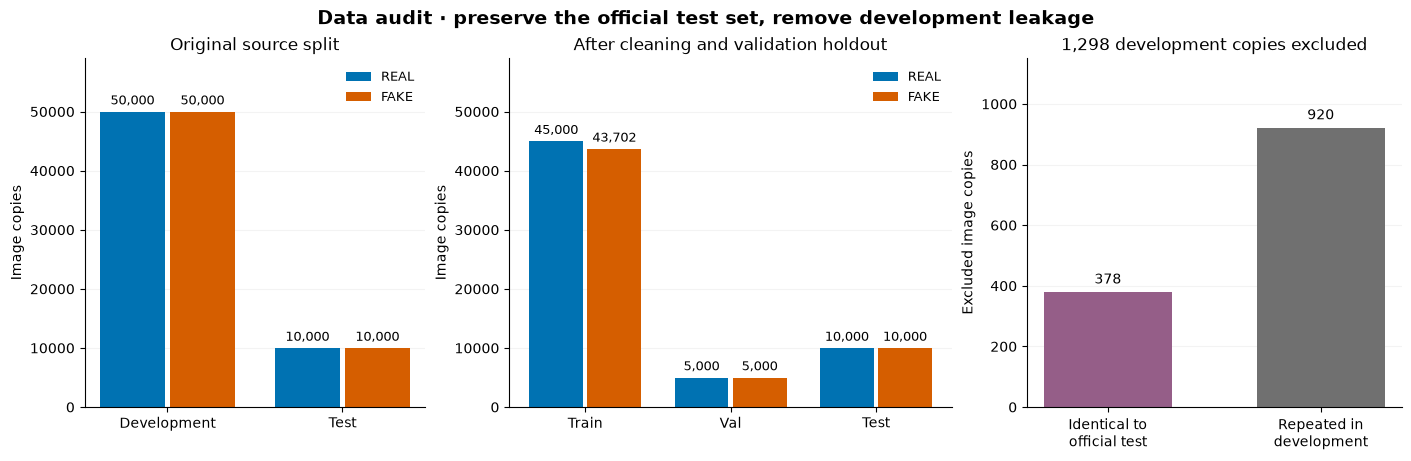

Original development/test overlap: 378 exact pixel hashes.
Final train/validation/test overlap: 0.
Official test contains 38 repeated copies.


In [12]:
if audit:
    if eda_manifest:
        original_counts = {
            source: {name: sum(row["source_split"] == source and row["class_name"] == name for row in eda_manifest)
                     for name, _ in EDA_CLASS_ORDER}
            for source in ("train", "test")
        }
        before_hashes = {source: {r["pixel_sha256"] for r in eda_manifest if r["source_split"] == source}
                         for source in ("train", "test")}
        overlap_before = len(before_hashes["train"] & before_hashes["test"])
        assert overlap_before == audit["exclusion_counts"]["identical_to_official_test"]
    else:
        original_counts = {
            "train": {name: sum(audit["split_counts"][s].get(name, 0) for s in ("train", "val", "excluded"))
                      for name, _ in EDA_CLASS_ORDER},
            "test": audit["split_counts"]["test"],
        }
        overlap_before = audit["exclusion_counts"]["identical_to_official_test"]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained",
                             gridspec_kw={"width_ratios": [1, 1.3, 1.1]})
    for ax, names, counts, title in [
        (axes[0], ["train", "test"], original_counts, "Original source split"),
        (axes[1], ["train", "val", "test"], audit["split_counts"], "After cleaning and validation holdout"),
    ]:
        positions = np.arange(len(names))
        for offset, (name, _) in zip([-0.2, 0.2], EDA_CLASS_ORDER):
            bars = ax.bar(positions + offset, [counts[s].get(name, 0) for s in names], width=0.37,
                          label=name, color=EDA_COLORS[name])
            ax.bar_label(bars, labels=[f"{int(b.get_height()):,}" for b in bars], padding=3, fontsize=9)
        ax.set(xticks=positions, xticklabels=["Development" if s == "train" and ax is axes[0] else s.title() for s in names],
               ylabel="Image copies", title=title, ylim=(0, 59000))
        ax.legend(frameon=False, fontsize=9)
        style_eda_axes(ax)
    reasons = ["Identical to\nofficial test", "Repeated in\ndevelopment"]
    values = [audit["exclusion_counts"]["identical_to_official_test"], audit["exclusion_counts"]["repeated_training_image"]]
    bars = axes[2].bar(reasons, values, color=["#955E88", "#707070"], width=0.6)
    axes[2].bar_label(bars, padding=4)
    axes[2].set(title=f"{sum(values):,} development copies excluded", ylabel="Excluded image copies", ylim=(0, max(values)*1.25))
    style_eda_axes(axes[2])
    fig.suptitle("Data audit · preserve the official test set, remove development leakage", fontsize=14, fontweight="bold")
    finish_eda_figure(fig, "01_split_audit")
    print(f"Original development/test overlap: {overlap_before:,} exact pixel hashes.")
    print(f"Final train/validation/test overlap: {audit['exact_pixel_overlap_across_splits']}.")
    print(f"Official test contains {audit['official_test_size'] - audit['unique_test_images']} repeated copies.")

To make those duplicate counts more concrete, we'll also look at three pairs of images from the original training pool. Each row will place a retained training image beside a repeated copy that was excluded, with the filenames shown above them. We choose these pairs from groups with exactly matching decoded pixels, then check the pixels again before displaying them. This shows why different filenames do not necessarily mean different examples. These are exact duplicates rather than merely similar-looking pictures, and neither side of the comparison comes from the test set.

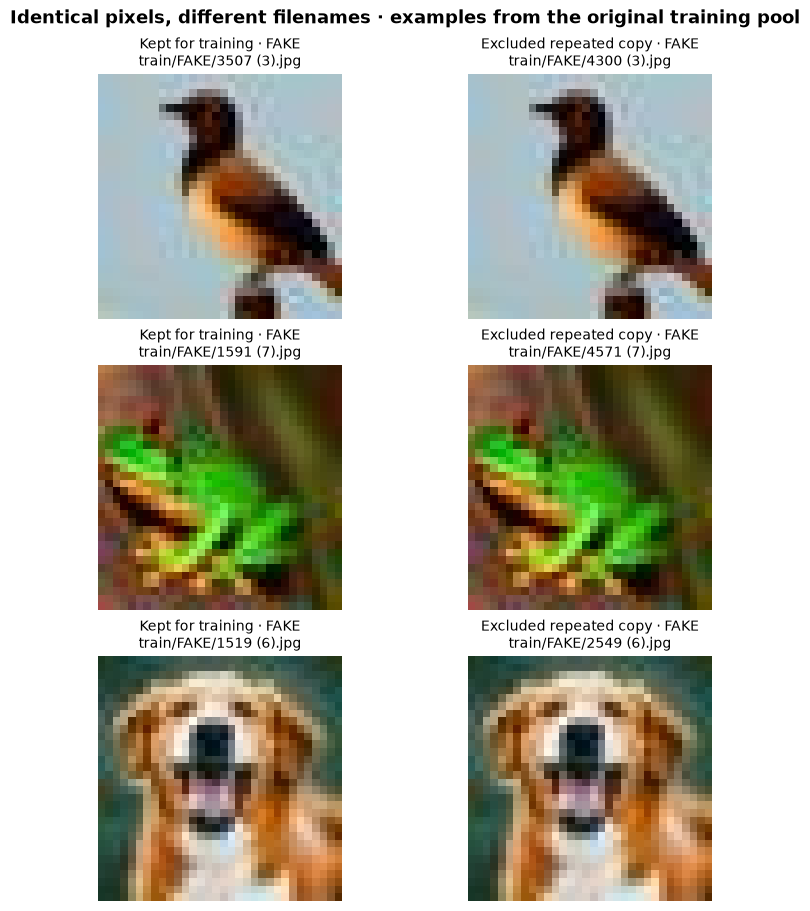

In [13]:
# Only display original-development pairs: one kept for TRAIN, one excluded repeat.
# Official test pixels are not opened for this illustration.
if eda_manifest and RAW_DATA.exists():
    duplicate_groups = defaultdict(list)
    for row in eda_manifest:
        if row["source_split"] == "train":
            duplicate_groups[row["pixel_sha256"]].append(row)
    duplicate_pairs = []
    for pixel_hash, group in sorted(duplicate_groups.items()):
        kept = next((r for r in group if r["split"] == "train"), None)
        excluded = next((r for r in group if r["exclusion_reason"] == "repeated_training_image"), None)
        if kept and excluded:
            duplicate_pairs.append((pixel_hash, kept, excluded))
    pair_rng = np.random.default_rng(EDA_SEED)
    chosen_pairs = [duplicate_pairs[i] for i in pair_rng.choice(len(duplicate_pairs), size=min(3, len(duplicate_pairs)), replace=False)]
    fig, axes = plt.subplots(len(chosen_pairs), 2, figsize=(7.4, 3.0*len(chosen_pairs)), squeeze=False, layout="constrained")
    for row_index, (pixel_hash, kept, excluded) in enumerate(chosen_pairs):
        pair_pixels = []
        for col, (record, role) in enumerate([(kept, "Kept for training"), (excluded, "Excluded repeated copy")]):
            assert record["path"].startswith("train/")
            with PILImage.open(RAW_DATA / record["path"]) as source_image:
                pixels = np.asarray(source_image.convert("RGB"))
            pair_pixels.append(pixels)
            axes[row_index, col].imshow(pixels, interpolation="nearest")
            axes[row_index, col].set_title(f"{role} · {record['class_name']}\n{record['path']}", fontsize=10)
            axes[row_index, col].axis("off")
        assert np.array_equal(*pair_pixels)
    fig.suptitle("Identical pixels, different filenames · examples from the original training pool", fontsize=13, fontweight="bold")
    finish_eda_figure(fig, "02_duplicate_examples")
    del duplicate_groups
else:
    show_saved_eda("02_duplicate_examples")

### 4.2 Balanced random gallery

Before reducing the images to numbers, it helps to get a feel for what the dataset actually looks like. We'll randomly select twelve real and twelve fake images from the cleaned training split and display them in a grid, with real images in the first two rows and fake images in the last two. A fixed random seed means everyone sees the same examples when rerunning the notebook. Look at the backgrounds, edges, textures, and overall composition, and consider which images would be difficult to classify by eye. The images are enlarged without smoothing so we can still see their original 32×32 pixels. This is a small random sample; the object categories are not matched between the two groups.

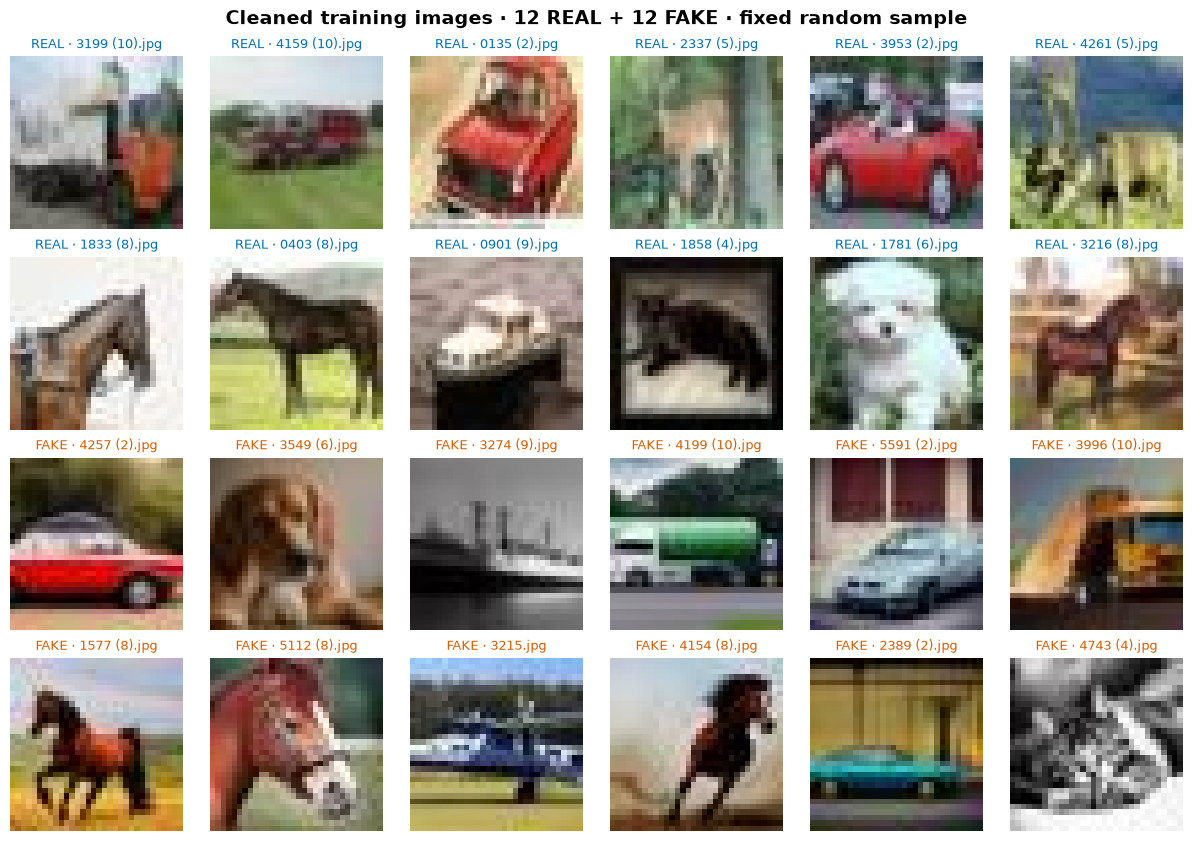

In [14]:
if eda_images is not None:
    gallery_rng = np.random.default_rng(EDA_SEED)
    fig, axes = plt.subplots(4, 6, figsize=(12, 8.3), layout="constrained")
    for class_index, (name, label) in enumerate(EDA_CLASS_ORDER):
        chosen = gallery_rng.choice(np.flatnonzero(eda_labels == label), size=12, replace=False)
        for local_index, image_index in enumerate(chosen):
            ax = axes[class_index*2 + local_index//6, local_index%6]
            ax.imshow(eda_images[image_index].transpose(1, 2, 0), interpolation="nearest")
            ax.set_title(f"{name} · {Path(eda_rows[image_index]['path']).name}", fontsize=9, color=EDA_COLORS[name])
            ax.axis("off")
    fig.suptitle("Cleaned training images · 12 REAL + 12 FAKE · fixed random sample", fontsize=14, fontweight="bold")
    finish_eda_figure(fig, "03_random_gallery")
else:
    show_saved_eda("03_random_gallery")

### 4.3 Image-property distributions

All four properties are calculated on native 32×32 pixels scaled to `[0, 1]`:

- **Brightness:** mean of luma `0.299 R + 0.587 G + 0.114 B`. This is a weighted pixel-value proxy, not calibrated physical luminance.
- **Contrast:** standard deviation of that luma within an image.
- **Saturation:** mean HSV saturation `(max(R,G,B) − min(R,G,B)) / max(R,G,B)`, with zero for black pixels.
- **Sharpness proxy:** variance of the four-neighbour discrete Laplacian, evaluated on the 30×30 interior to avoid padding artifacts. This also responds to noise and compression; it does not measure perceptual sharpness alone.

The sharpness plot uses `log10(variance + 1e-8)` to show its skewed range. Both classes use the same bin edges, and each histogram is normalized separately to density because their training counts differ slightly. No observations are trimmed.

In [15]:
def compute_training_properties(images, labels, batch_size=1024):
    """Four image properties and equal-image-weight, normalized 2-D spectra."""
    properties = np.empty((len(images), 4), dtype=np.float64)
    spectrum_sums = {label: np.zeros((32, 32), dtype=np.float64) for label in (0, 1)}
    spectrum_counts = {label: 0 for label in (0, 1)}
    window = np.outer(np.hanning(32), np.hanning(32)).astype(np.float32)
    weights = np.array([0.299, 0.587, 0.114], dtype=np.float32)
    for start in range(0, len(images), batch_size):
        stop = min(start + batch_size, len(images))
        rgb = images[start:stop].astype(np.float32) / 255
        luma = np.einsum("nchw,c->nhw", rgb, weights)
        channel_max, channel_min = rgb.max(axis=1), rgb.min(axis=1)
        saturation = np.divide(channel_max-channel_min, channel_max,
                               out=np.zeros_like(channel_max), where=channel_max > 0)
        laplacian = (luma[:, :-2, 1:-1] + luma[:, 2:, 1:-1] + luma[:, 1:-1, :-2]
                     + luma[:, 1:-1, 2:] - 4*luma[:, 1:-1, 1:-1])
        properties[start:stop] = np.column_stack([
            luma.mean(axis=(1, 2)), luma.std(axis=(1, 2)),
            saturation.mean(axis=(1, 2)), laplacian.var(axis=(1, 2)),
        ])
        # A Hann window limits boundary discontinuities; weighted centering removes DC.
        weighted_mean = (luma*window).sum(axis=(1, 2), keepdims=True) / window.sum()
        transformed = np.fft.fftshift(np.fft.fft2((luma-weighted_mean)*window, axes=(-2, -1)), axes=(-2, -1))
        power = np.abs(transformed)**2
        power[:, 16, 16] = 0
        total_energy = power.sum(axis=(1, 2), keepdims=True)
        nonconstant = luma.std(axis=(1, 2)) > 1e-7
        valid = nonconstant & (total_energy[:, 0, 0] > 1e-12)
        normalized = np.divide(power, total_energy, out=np.zeros_like(power), where=total_energy > 1e-12)
        for label in (0, 1):
            mask = (labels[start:stop] == label) & valid
            spectrum_sums[label] += normalized[mask].sum(axis=0, dtype=np.float64)
            spectrum_counts[label] += int(mask.sum())
    spectra = {label: spectrum_sums[label]/max(spectrum_counts[label], 1) for label in (0, 1)}
    return properties, spectra, spectrum_counts

# Sanity checks have known properties: constant gray, solid red, and a checkerboard.
check_images = np.full((3, 3, 32, 32), 102, dtype=np.uint8)
check_images[1] = 0
check_images[1, 0] = 255
checker = ((np.indices((32, 32)).sum(axis=0) % 2)*255).astype(np.uint8)
check_images[2] = np.repeat(checker[None, :, :], 3, axis=0)
check_properties, _, check_spectra_counts = compute_training_properties(check_images, np.array([0, 0, 1]))
assert np.allclose(check_properties[0], [0.4, 0, 0, 0], atol=1e-6)
assert np.isclose(check_properties[1, 0], 0.299, atol=1e-6) and np.isclose(check_properties[1, 2], 1)
assert check_properties[2, 3] > check_properties[0, 3]
assert check_spectra_counts == {0: 0, 1: 1}

eda_features, eda_spectra, eda_spectrum_counts = None, None, None
eda_property_stats = {}
if eda_images is not None:
    eda_features, eda_spectra, eda_spectrum_counts = compute_training_properties(eda_images, eda_labels)
    assert np.isfinite(eda_features).all() and (eda_features >= 0).all()
    assert (eda_features[:, [0, 2]] <= 1 + 1e-6).all()
    assert all(np.isclose(spectrum.sum(), 1, atol=1e-5) for spectrum in eda_spectra.values())
    for name, label in EDA_CLASS_ORDER:
        class_features = eda_features[eda_labels == label]
        eda_property_stats[name] = {
            prop: {"mean": float(np.mean(class_features[:, col])), "median": float(np.median(class_features[:, col])),
                   "p10": float(np.quantile(class_features[:, col], 0.1)), "p90": float(np.quantile(class_features[:, col], 0.9))}
            for col, prop in enumerate(EDA_PROPERTIES)
        }
    print(f"Computed image properties and spectra for all {len(eda_features):,} cleaned training images.")
    print("Numerical checks passed; each class-average normalized spectrum sums to 1.")

Computed image properties and spectra for all 88,702 cleaned training images.
Numerical checks passed; each class-average normalized spectrum sums to 1.


The next four plots will help us see whether the impressions from the gallery hold across the whole training set. For every image, we'll calculate brightness, contrast, saturation, and a sharpness score, then group the values into bins and overlay the real and fake distributions. Blue represents real images and orange represents fake images. Both groups use the same bins, and each distribution is scaled to have a total area of one so their slightly different image counts do not distort the comparison. The dashed lines mark the medians. Look for shifts in the typical values as well as the amount of overlap; a difference in the medians does not mean that a property can reliably identify every image. Sharpness is shown on a logarithmic scale to make its wide range easier to read.

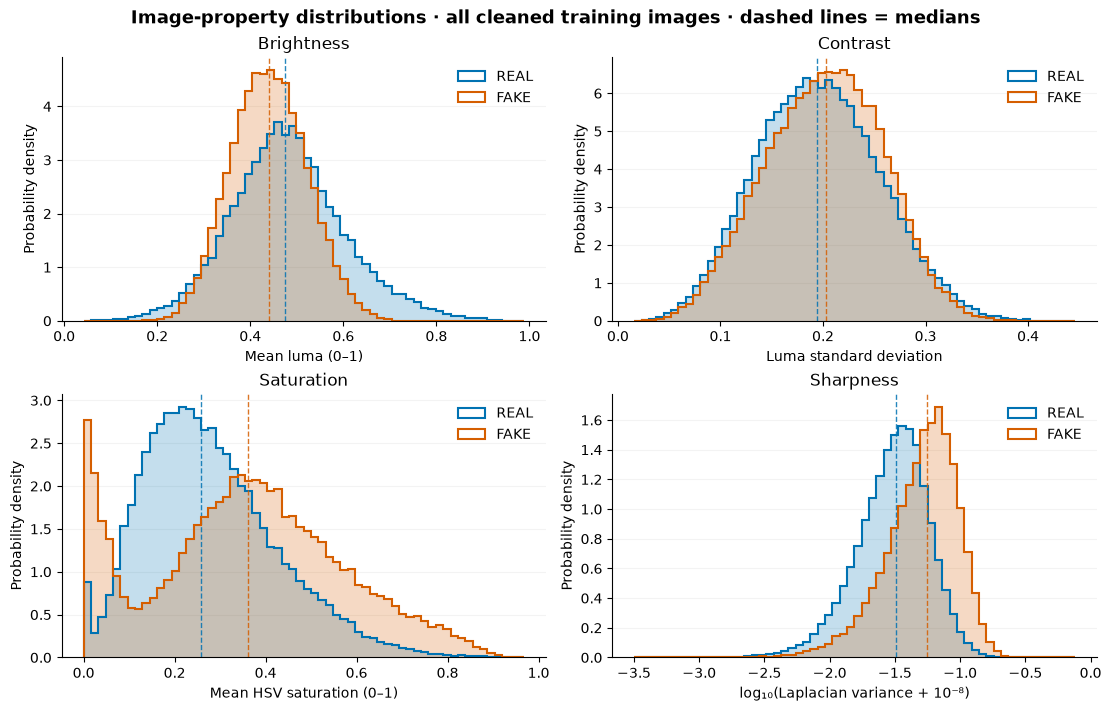

| Property (original units) | Class | Mean | Median | 10th–90th percentile |
| --- | --- | --- | --- | --- |
| brightness | REAL | 0.4809 | 0.4755 | 0.3317–0.6397 |
| brightness | FAKE | 0.4407 | 0.4395 | 0.3363–0.5466 |
| contrast | REAL | 0.1961 | 0.1946 | 0.1189–0.2749 |
| contrast | FAKE | 0.2014 | 0.2031 | 0.1257–0.2738 |
| saturation | REAL | 0.2785 | 0.2588 | 0.1086–0.4804 |
| saturation | FAKE | 0.3592 | 0.361 | 0.04454–0.6392 |
| sharpness | REAL | 0.0363 | 0.03212 | 0.01311–0.06413 |
| sharpness | FAKE | 0.06011 | 0.05531 | 0.02174–0.1042 |

In [16]:
if eda_features is not None:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for col, (prop, ax) in enumerate(zip(EDA_PROPERTIES, axes.flat)):
        values = np.log10(eda_features[:, col]+1e-8) if prop == "sharpness" else eda_features[:, col]
        bins = np.linspace(values.min(), values.max(), 61)
        for name, label in EDA_CLASS_ORDER:
            group = values[eda_labels == label]
            ax.hist(group, bins=bins, density=True, histtype="stepfilled", alpha=0.23, color=EDA_COLORS[name])
            ax.hist(group, bins=bins, density=True, histtype="step", lw=1.5, color=EDA_COLORS[name], label=name)
            ax.axvline(np.median(group), color=EDA_COLORS[name], ls="--", lw=1, alpha=0.85)
        key = "log_sharpness" if prop == "sharpness" else prop
        ax.set(title=prop.title(), xlabel=EDA_PROPERTY_LABELS[key], ylabel="Probability density")
        ax.legend(frameon=False)
        style_eda_axes(ax)
    fig.suptitle("Image-property distributions · all cleaned training images · dashed lines = medians", fontsize=13, fontweight="bold")
    finish_eda_figure(fig, "04_property_distributions")
    show_table(["Property (original units)", "Class", "Mean", "Median", "10th–90th percentile"], [
        [prop, name, f"{eda_property_stats[name][prop]['mean']:.4g}", f"{eda_property_stats[name][prop]['median']:.4g}",
         f"{eda_property_stats[name][prop]['p10']:.4g}–{eda_property_stats[name][prop]['p90']:.4g}"]
        for prop in EDA_PROPERTIES for name, _ in EDA_CLASS_ORDER
    ])
else:
    show_saved_eda("04_property_distributions")

### 4.4 Connect the sharpness proxy to actual images

A sharpness score is easier to understand when we can see the images behind it. We'll rank the training images by Laplacian variance and display the four lowest-scoring and four highest-scoring examples separately for real and fake images. The low-score rows will let us inspect images with little variation in local edges, while the high-score rows will show what produces a strong response. As we compare them, we'll look for blur, detailed textures, repeated patterns, or noise that might explain the scores. These examples were deliberately chosen from the extremes, so they should not be treated as typical real or fake images. A high value also does not automatically mean better image quality.

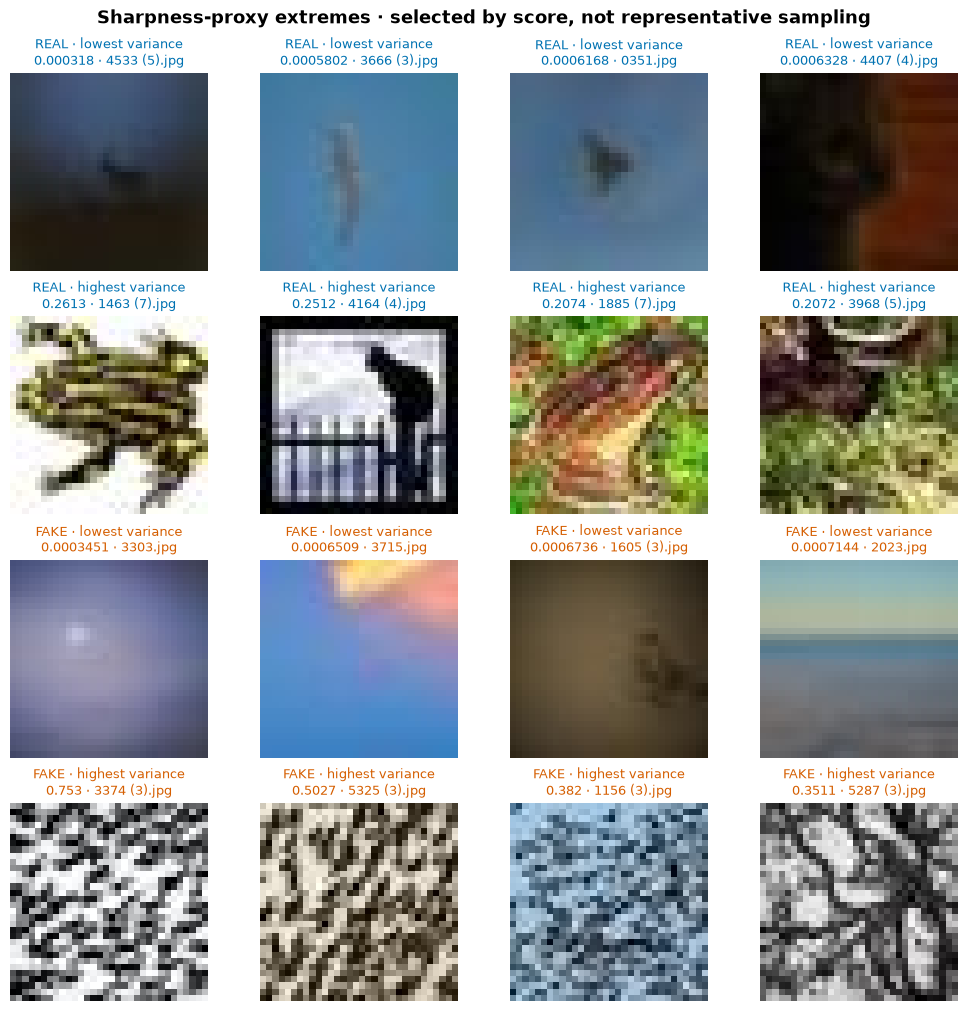

In [17]:
if eda_features is not None:
    fig, axes = plt.subplots(4, 4, figsize=(10, 10), layout="constrained")
    for class_index, (name, label) in enumerate(EDA_CLASS_ORDER):
        members = np.flatnonzero(eda_labels == label)
        ordered = members[np.argsort(eda_features[members, 3], kind="stable")]
        for which, selected in enumerate([ordered[:4], ordered[-4:][::-1]]):
            for col, index in enumerate(selected):
                ax = axes[2*class_index+which, col]
                ax.imshow(eda_images[index].transpose(1, 2, 0), interpolation="nearest")
                ax.set_title(f"{name} · {'lowest' if which == 0 else 'highest'} variance\n{eda_features[index, 3]:.4g} · {Path(eda_rows[index]['path']).name}",
                             fontsize=9, color=EDA_COLORS[name])
                ax.axis("off")
    fig.suptitle("Sharpness-proxy extremes · selected by score, not representative sampling", fontsize=13, fontweight="bold")
    finish_eda_figure(fig, "05_sharpness_extremes")
else:
    show_saved_eda("05_sharpness_extremes")

### 4.5 Link image properties to thumbnails

The histograms show one property at a time, but two properties may tell a different story when we look at them together. Here we'll plot the sharpness score on the horizontal axis, using a logarithmic scale, and contrast on the vertical axis. Each point represents one training image, with blue for real images and orange for fake images. We'll use a fixed random sample of 800 images from each group to keep the plot readable and give both classes equal representation. Look for any relationship between contrast and sharpness, for points that sit far from the others, and for regions where the two colours overlap. The colours show the dataset labels; no model predictions are involved in this plot.

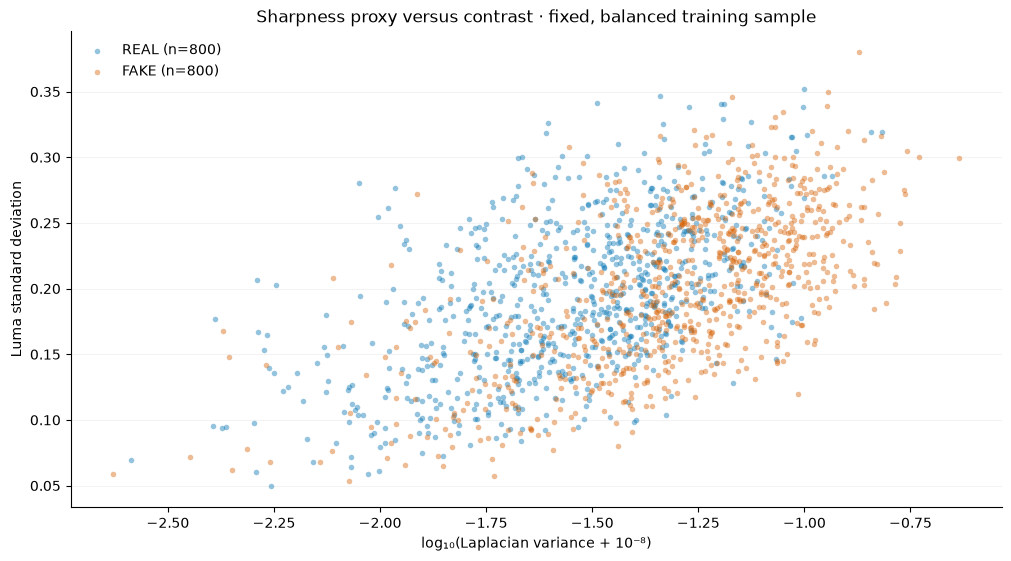

In [18]:
eda_scatter_indices = None
if eda_features is not None:
    scatter_rng = np.random.default_rng(EDA_SEED)
    eda_scatter_indices = np.concatenate([
        scatter_rng.choice(np.flatnonzero(eda_labels == label), size=min(800, int((eda_labels == label).sum())), replace=False)
        for _, label in EDA_CLASS_ORDER
    ])
    eda_plot_values = {prop: eda_features[:, col] for col, prop in enumerate(EDA_PROPERTIES)}
    eda_plot_values["log_sharpness"] = np.log10(eda_features[:, 3]+1e-8)
    fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
    for name, label in EDA_CLASS_ORDER:
        ids = eda_scatter_indices[eda_labels[eda_scatter_indices] == label]
        ax.scatter(eda_plot_values["log_sharpness"][ids], eda_plot_values["contrast"][ids],
                   c=EDA_COLORS[name], s=16, alpha=0.42, linewidths=0, label=f"{name} (n={len(ids)})")
    ax.set(xlabel=EDA_PROPERTY_LABELS["log_sharpness"], ylabel=EDA_PROPERTY_LABELS["contrast"],
           title="Sharpness proxy versus contrast · fixed, balanced training sample")
    style_eda_axes(ax)
    ax.legend(frameon=False)
    finish_eda_figure(fig, "06_scatter_overview")
else:
    show_saved_eda("06_scatter_overview")

We can now connect those points back to the actual pictures. The interactive version uses the same sampled images, but lets us change the properties on either axis, zoom into a region, and hide or show a class through the legend. Clicking a point will display its image, filename, and measurements below the chart. For example, we can select a point with unusually high sharpness and inspect whether it contains fine texture or a noisy pattern. This gives us a way to investigate patterns rather than guess what an isolated point represents. Run the cell with a live notebook kernel and the prepared training data to enable the interactions; the static plot above remains available on GitHub.

In [19]:
if eda_scatter_indices is not None:
    try:
        import plotly.graph_objects as go
        import ipywidgets as widgets
        import anywidget  # FigureWidget's Jupyter widget backend
    except ImportError:
        print("Install the pinned requirements and restart the kernel for the clickable explorer. The static scatterplot remains available above.")
    else:
        explorer_ids = {name: eda_scatter_indices[eda_labels[eda_scatter_indices] == label]
                        for name, label in EDA_CLASS_ORDER}
        axis_options = [(EDA_PROPERTY_LABELS[key], key)
                        for key in ("brightness", "contrast", "saturation", "log_sharpness")]
        explorer_x = widgets.Dropdown(options=axis_options, value="log_sharpness", description="X axis:",
                                     layout=widgets.Layout(width="47%"))
        explorer_y = widgets.Dropdown(options=axis_options, value="contrast", description="Y axis:",
                                     layout=widgets.Layout(width="47%"))
        explorer_figure = go.FigureWidget()
        for name, _ in EDA_CLASS_ORDER:
            ids = explorer_ids[name]
            explorer_figure.add_scatter(
                x=eda_plot_values[explorer_x.value][ids], y=eda_plot_values[explorer_y.value][ids],
                name=name, mode="markers", customdata=[eda_rows[int(i)]["path"] for i in ids],
                marker=dict(size=6, color=EDA_COLORS[name], opacity=0.55),
                hovertemplate="%{customdata}<br>x=%{x:.4f}<br>y=%{y:.4f}<extra>%{fullData.name}</extra>",
            )
        explorer_figure.add_scatter(x=[], y=[], name="Selected", mode="markers", hoverinfo="skip",
                                    showlegend=False, marker=dict(size=16, color="#242424", symbol="circle-open", line=dict(width=2)))
        explorer_figure.update_layout(
            template="plotly_white", height=440, margin=dict(l=65, r=20, t=55, b=60),
            title="Click a training-image point to inspect it below", clickmode="event",
            xaxis_title=EDA_PROPERTY_LABELS[explorer_x.value], yaxis_title=EDA_PROPERTY_LABELS[explorer_y.value],
            legend=dict(orientation="h", y=1.05, x=0.75),
        )
        explorer_image = widgets.Image(format="png", width=160, height=160)
        explorer_details = widgets.HTML(layout=widgets.Layout(margin="0 0 0 18px"))
        explorer_selection = {"index": int(explorer_ids["REAL"][0])}

        def select_training_image(index):
            index = int(index)
            assert eda_rows[index]["split"] == "train"
            explorer_selection["index"] = index
            buffer = BytesIO()
            PILImage.fromarray(eda_images[index].transpose(1, 2, 0)).resize(
                (160, 160), resample=PILImage.Resampling.NEAREST).save(buffer, format="PNG")
            explorer_image.value = buffer.getvalue()
            name = "REAL" if eda_labels[index] == 1 else "FAKE"
            stats_html = "<br>".join(f"{html.escape(EDA_PROPERTY_LABELS[prop])}: <b>{eda_features[index, col]:.4f}</b>"
                                   for col, prop in enumerate(EDA_PROPERTIES))
            explorer_details.value = (f"<b style='color:{EDA_COLORS[name]}'>{name}</b> · training image<br>"
                                      f"<code>{html.escape(eda_rows[index]['path'])}</code><br><br>{stats_html}"
                                      "<br><small>32×32 source, enlarged with nearest-neighbor sampling.</small>")
            with explorer_figure.batch_update():
                explorer_figure.data[2].x = [eda_plot_values[explorer_x.value][index]]
                explorer_figure.data[2].y = [eda_plot_values[explorer_y.value][index]]

        def on_training_image_click(trace, points, selector):
            if points.point_inds:
                select_training_image(explorer_ids[trace.name][points.point_inds[0]])

        def update_explorer_axes(change):
            with explorer_figure.batch_update():
                for trace in explorer_figure.data[:2]:
                    ids = explorer_ids[trace.name]
                    trace.x = eda_plot_values[explorer_x.value][ids]
                    trace.y = eda_plot_values[explorer_y.value][ids]
                explorer_figure.layout.xaxis.title = EDA_PROPERTY_LABELS[explorer_x.value]
                explorer_figure.layout.yaxis.title = EDA_PROPERTY_LABELS[explorer_y.value]
                index = explorer_selection["index"]
                explorer_figure.data[2].x = [eda_plot_values[explorer_x.value][index]]
                explorer_figure.data[2].y = [eda_plot_values[explorer_y.value][index]]

        for trace in explorer_figure.data[:2]:
            trace.on_click(on_training_image_click)
        explorer_x.observe(update_explorer_axes, names="value")
        explorer_y.observe(update_explorer_axes, names="value")
        select_training_image(explorer_selection["index"])
        display(widgets.VBox([
            widgets.HBox([explorer_x, explorer_y]), explorer_figure,
            widgets.HBox([explorer_image, explorer_details]),
        ]))
        print("Requires a running notebook kernel for thumbnail clicks and axis changes. The static plot above works in GitHub previews.")
else:
    print("Interactive thumbnails need the prepared training data. Saved static plots above can be reviewed without it.")

Requires a running notebook kernel for thumbnail clicks and axis changes. The static plot above works in GitHub previews.


### 4.6 Spatial-frequency patterns

Next we'll compare how broad shapes and fine detail are distributed across the two groups. We'll convert each training image to a single brightness channel and use a Fourier transform to describe its spatial-frequency content. Slowly changing areas contribute to lower frequencies, while finer textures and rapid changes between neighbouring pixels contribute to higher frequencies. Averaging the results separately for real and fake images will give us the two heatmaps below. Their centres represent low frequencies, and positions farther from the centre represent finer detail. Both heatmaps use the same colour scale, so their intensities can be compared directly.

To make the comparison fair, we subtract each image's Hann-weighted mean, apply a Hann window to soften boundary effects, and remove the zero-frequency bin, which represents the average brightness. We then scale each usable image's remaining power to sum to one before averaging, so high-contrast images do not dominate the result. Constant or effectively zero-energy images are excluded and counted below. The colours use a logarithmic scale so weaker frequency components remain visible.

The line plot on the right will make the comparison easier to follow by averaging bins at similar distances from the centre. Moving right corresponds to finer detail; a higher curve means more normalized power per frequency bin at that distance. This is not the total energy in each ring. Frequencies are measured in cycles per pixel, and diagonal distances can exceed 0.5. We'll look for ranges where the curves differ, while keeping in mind that image content, compression, and other processing can also produce these differences. The plots alone cannot tell us whether the CNN uses them.

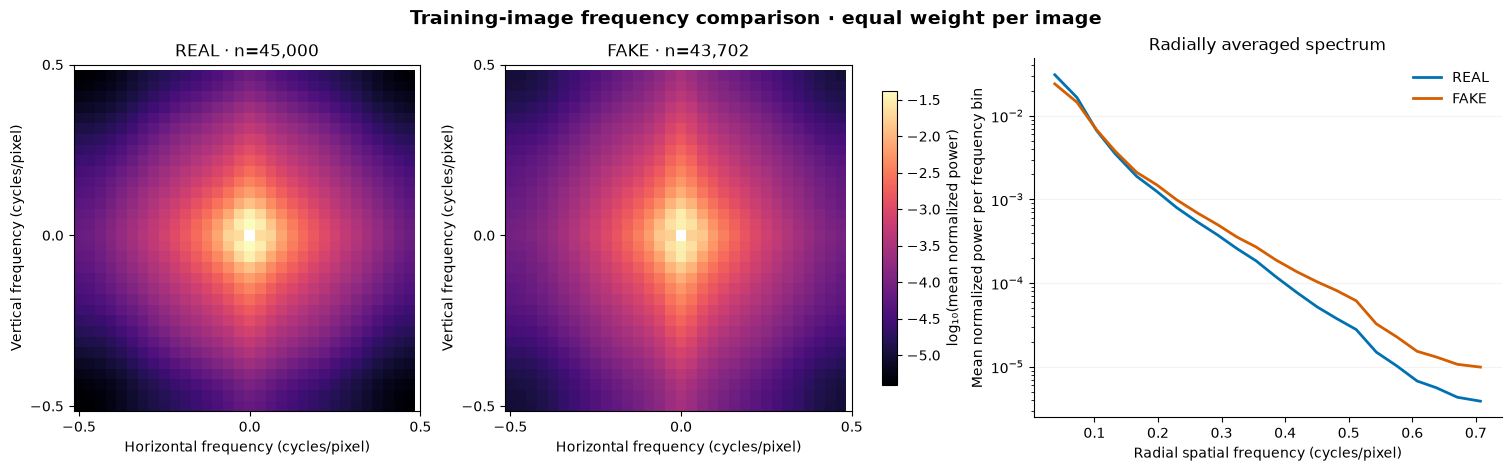

REAL: 45,000 usable spectra; 0 constant/zero-energy images excluded.
FAKE: 43,702 usable spectra; 0 constant/zero-energy images excluded.


In [20]:
if eda_spectra is not None:
    frequencies = np.fft.fftshift(np.fft.fftfreq(32))
    freq_x, freq_y = np.meshgrid(frequencies, frequencies)
    eda_frequency_radius = np.hypot(freq_x, freq_y)
    rings = np.floor(eda_frequency_radius * 32).astype(int)
    ring_counts = np.bincount(rings.ravel())
    ring_radius = np.bincount(rings.ravel(), weights=eda_frequency_radius.ravel()) / ring_counts
    nonzero_rings = (ring_counts > 0) & (np.arange(len(ring_counts)) > 0)
    log_spectra = {label: np.ma.masked_where(eda_frequency_radius == 0, np.log10(spectrum+1e-12))
                   for label, spectrum in eda_spectra.items()}
    color_min = min(float(s.min()) for s in log_spectra.values())
    color_max = max(float(s.max()) for s in log_spectra.values())
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained",
                             gridspec_kw={"width_ratios": [1, 1, 1.35]})
    for ax, (name, label) in zip(axes[:2], EDA_CLASS_ORDER):
        heat = ax.imshow(log_spectra[label], origin="lower", cmap="magma", vmin=color_min, vmax=color_max,
                         extent=(-0.5-1/64, 0.5-1/64, -0.5-1/64, 0.5-1/64), interpolation="nearest")
        ax.set(title=f"{name} · n={eda_spectrum_counts[label]:,}", xlabel="Horizontal frequency (cycles/pixel)",
               ylabel="Vertical frequency (cycles/pixel)", xticks=[-0.5, 0, 0.5], yticks=[-0.5, 0, 0.5])
    colorbar = fig.colorbar(heat, ax=list(axes[:2]), shrink=0.82, pad=0.025)
    colorbar.set_label("log₁₀(mean normalized power)")
    for name, label in EDA_CLASS_ORDER:
        profile = np.bincount(rings.ravel(), weights=eda_spectra[label].ravel()) / ring_counts
        axes[2].plot(ring_radius[nonzero_rings], profile[nonzero_rings], color=EDA_COLORS[name],
                     label=name, linewidth=2)
    axes[2].set(xlabel="Radial spatial frequency (cycles/pixel)", ylabel="Mean normalized power per frequency bin",
                title="Radially averaged spectrum", yscale="log")
    axes[2].legend(frameon=False)
    style_eda_axes(axes[2])
    fig.suptitle("Training-image frequency comparison · equal weight per image", fontweight="bold", fontsize=14)
    finish_eda_figure(fig, "07_frequency_comparison")
    for name, label in EDA_CLASS_ORDER:
        excluded = int((eda_labels == label).sum()) - eda_spectrum_counts[label]
        print(f"{name}: {eda_spectrum_counts[label]:,} usable spectra; {excluded} constant/zero-energy images excluded.")
else:
    show_saved_eda("07_frequency_comparison")

### 4.7 Record the observations

The completed figures and numerical summary are bundled inside this notebook. Set `SAVE_FIGURES = True` to also save recalculated figures locally in `results/eda_baseline_seed1/`. Galleries and the scatterplot use seed 2026; property distributions and frequency averages use the entire cleaned training split. Thumbnail enlargement is for display only and is not training augmentation.

Read the property medians together with the distributions and example images. Class distributions can overlap substantially even when their medians differ. These plots generate hypotheses for later validation-set experiments, such as blur or color perturbations; they do not establish which cues the CNN learned. Keep the completed baseline and test results fixed when designing those follow-up experiments.

In [21]:
eda_summary = None
if eda_features is not None:
    eda_summary = {
        "source_split": "train", "split_seed": SPLIT_SEED, "sampling_seed": EDA_SEED,
        "manifest_sha256": file_sha256(DATA_DIR / "manifest.csv"),
        "image_shape_chw": list(eda_images.shape[1:]), "image_count": len(eda_images),
        "class_counts": {name: int((eda_labels == label).sum()) for name, label in EDA_CLASS_ORDER},
        "property_definitions": {
            "brightness": "Mean of 0.299R + 0.587G + 0.114B, RGB scaled to [0,1]",
            "contrast": "Population standard deviation of luma",
            "saturation": "Mean HSV saturation: (max(RGB)-min(RGB))/max(RGB), zero for black pixels",
            "sharpness": "Population variance of the four-neighbor luma Laplacian over the 30x30 interior",
        },
        "property_statistics": eda_property_stats,
        "frequency_method": "Hann-weighted centering, 2-D Hann window, FFT power, DC removed, per-image unit-sum normalization, class mean",
        "spectrum_counts": {name: eda_spectrum_counts[label] for name, label in EDA_CLASS_ORDER},
        "excluded_spectrum_counts": {name: int((eda_labels == label).sum())-eda_spectrum_counts[label]
                                     for name, label in EDA_CLASS_ORDER},
        "mean_energy_fraction_radius_ge_0_25": {
            name: float(eda_spectra[label][eda_frequency_radius >= 0.25].sum()) for name, label in EDA_CLASS_ORDER},
        "gallery_images_per_class": 12, "scatter_images_per_class": 800,
        "figures": [p.name for p in sorted(EDA_DIR.glob("*.png"))],
        "scope": "Training pixels only; split audit also reads metadata for all splits. Added after the baseline run; no model or test-result changes.",
        "limitations": ["Descriptive class associations do not establish model reliance or causation.",
                        "Sharpness is a resolution-dependent proxy, not a direct measure of image quality.",
                        "Near-duplicates and semantic-category balance were not audited."],
    }
    if SAVE_FIGURES:
        write_json(EDA_DIR / "summary.json", eda_summary)
        print("Saved seven figures and summary:", EDA_DIR.relative_to(ROOT))
    else:
        print("Figures and observations are displayed inline; SAVE_FIGURES enables optional local copies.")
else:
    eda_summary = read_json(EDA_DIR / "summary.json") if (EDA_DIR / "summary.json").exists() else None
    if eda_summary is None and SPLIT_SEED == 1:
        eda_summary = json.loads(embedded_bytes("results/eda_baseline_seed1/summary.json"))

if eda_summary:
    property_stats = eda_summary["property_statistics"]
    real_median = property_stats["REAL"]["sharpness"]["median"]
    fake_median = property_stats["FAKE"]["sharpness"]["median"]
    display(Markdown(
        f"**Observed in {eda_summary['image_count']:,} training images:** median Laplacian variance is "
        f"**{real_median:.4f} for REAL** and **{fake_median:.4f} for FAKE**. "
        "Use the distributions and extreme-image gallery above to interpret that difference; "
        "this is an image statistic, not a model attribution."
    ))

Figures and observations are displayed inline; SAVE_FIGURES enables optional local copies.


**Observed in 88,702 training images:** median Laplacian variance is **0.0321 for REAL** and **0.0553 for FAKE**. Use the distributions and extreme-image gallery above to interpret that difference; this is an image statistic, not a model attribution.

## 5. The baseline network

The architecture follows the small-CNN direction in [the CIFAKE paper, Section 4.2 and Figure 5](https://arxiv.org/html/2303.14126v1): two convolutional layers with 32 filters and a 64-unit dense layer. Our kernel/pooling choices, split, Adam optimizer, and stopping settings are documented implementation choices, so this is **paper-inspired**, not an exact reproduction.

`32×32 RGB → Conv(32) → ReLU → MaxPool → Conv(32) → ReLU → MaxPool → Flatten → Dense(64) → ReLU → 1 logit`

There are **84,001 trainable parameters**. Preprocessing is only `float32 / 255`. There is no pretraining, dropout, batch normalization, weight decay, or augmentation. `FAKE=0`, `REAL=1`; the sigmoid of the output is **P(REAL)**. Training uses `BCEWithLogitsLoss`, which includes the sigmoid internally.

The model class is defined in the notebook implementation above. The next cell displays its layers and checks its parameter count.

In [22]:
architecture_preview = BaselineCNN()
print(architecture_preview)
print("Trainable parameters:", f"{sum(p.numel() for p in architecture_preview.parameters()):,}")
print("Label mapping:", LABELS)
del architecture_preview

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1152, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 84,001
Label mapping: {'FAKE': 0, 'REAL': 1}


## 6. Training and automatic checkpoints

Training uses Adam with the settings above. The learning rate is halved after a validation-loss plateau; early stopping triggers after five epochs without an improvement of at least 0.0001. The checkpoint with the **lowest validation BCE**, rather than the highest accuracy, is selected.

Every completed epoch saves model weights, optimizer, scheduler, random states, and metrics. `last.pt` is the recovery point; `best.pt` is the validation-selected model. Saves use a temporary file and atomic replacement. Interrupting the kernel can lose the unfinished epoch; completed epochs stay on disk.

The cell calls `train_model`, defined entirely in this notebook. A copy of the notebook and executed-code history is saved with each new run. Progress is printed here and written to `training.log`. Training never loads test images. In `review` mode, the cell reads the existing result.

In [23]:
if MODE == "train":
    train_model(data_dir=DATA_DIR, output=RUN_DIR, device=DEVICE, **TRAINING)
elif MODE == "resume":
    train_model(data_dir=DATA_DIR, output=RUN_DIR, device=DEVICE, resume=True)
else:
    print("Review mode: loading saved training results; no new training was run.")

run_summary = read_result("summary.json")
if run_summary:
    selected_epoch = run_summary.get("best_epoch", run_summary.get("selected_epoch"))
    print(f"Completed epochs: {run_summary['epochs_run']} | Selected epoch: {selected_epoch}")
    print(f"Validation accuracy of selected model: {run_summary['validation']['accuracy']:.2%}")
else:
    selected_epoch = None
    print("No completed result for this run yet.")

Review mode: loading saved training results; no new training was run.
Completed epochs: 24 | Selected epoch: 19
Validation accuracy of selected model: 94.54%


## 7. Inspect checkpoints or resume after interruption

To resume, change `MODE = "resume"`, keep `RUN_NAME` pointing to the interrupted run, and rerun configuration and training. Data integrity is checked by content hashes, so teammates can place the data under their own checkout. Resume restores the original settings and random states.

The completed baseline has already been test-evaluated and is kept fixed. Start a new named experiment for further training. A synthetic-data check verifies that resumed and uninterrupted CPU training produce identical weights and metrics; bitwise identity across devices is not guaranteed.

The table below uses recorded training history. On a clone without the full run archive, rows still show the history but checkpoint files will be marked absent.

In [24]:
history = read_result("history.csv") or []
if history:
    show_table(["Epoch", "Train loss", "Val loss", "Val accuracy", "Checkpoint", "Selected"], [
        [row["epoch"], f"{float(row['train_loss']):.4f}", f"{float(row['val_loss']):.4f}",
         f"{float(row['val_accuracy']):.2%}",
         "saved locally" if (RUN_DIR / "checkpoints" / f"epoch_{int(row['epoch']):03d}.pt").exists() else "archive needed",
         "yes" if int(row["epoch"]) == selected_epoch else ""]
        for row in history
    ])
    print("Best checkpoint:", "available" if (RUN_DIR / "best.pt").exists() else "selected inference weights are bundled in this notebook")
    print("Last checkpoint:", "available" if (RUN_DIR / "last.pt").exists() else "full archive needed to resume")

| Epoch | Train loss | Val loss | Val accuracy | Checkpoint | Selected |
| --- | --- | --- | --- | --- | --- |
| 1 | 0.3926 | 0.2891 | 87.55% | archive needed |  |
| 2 | 0.2719 | 0.2422 | 89.81% | archive needed |  |
| 3 | 0.2255 | 0.2036 | 92.12% | archive needed |  |
| 4 | 0.2003 | 0.1838 | 92.81% | archive needed |  |
| 5 | 0.1862 | 0.1820 | 92.82% | archive needed |  |
| 6 | 0.1727 | 0.1732 | 93.22% | archive needed |  |
| 7 | 0.1629 | 0.1698 | 93.22% | archive needed |  |
| 8 | 0.1558 | 0.1872 | 92.77% | archive needed |  |
| 9 | 0.1484 | 0.1621 | 93.83% | archive needed |  |
| 10 | 0.1445 | 0.1540 | 94.03% | archive needed |  |
| 11 | 0.1342 | 0.1581 | 93.82% | archive needed |  |
| 12 | 0.1308 | 0.1566 | 93.85% | archive needed |  |
| 13 | 0.1249 | 0.1780 | 93.28% | archive needed |  |
| 14 | 0.1032 | 0.1553 | 93.98% | archive needed |  |
| 15 | 0.1007 | 0.1427 | 94.49% | archive needed |  |
| 16 | 0.0987 | 0.1496 | 94.30% | archive needed |  |
| 17 | 0.0936 | 0.1542 | 94.38% | archive needed |  |
| 18 | 0.0917 | 0.1599 | 94.01% | archive needed |  |
| 19 | 0.0791 | 0.1421 | 94.54% | archive needed | yes |
| 20 | 0.0761 | 0.1641 | 94.30% | archive needed |  |
| 21 | 0.0745 | 0.1445 | 94.37% | archive needed |  |
| 22 | 0.0726 | 0.1469 | 94.72% | archive needed |  |
| 23 | 0.0662 | 0.1493 | 94.68% | archive needed |  |
| 24 | 0.0652 | 0.1481 | 94.68% | archive needed |  |

Best checkpoint: selected inference weights are bundled in this notebook
Last checkpoint: full archive needed to resume


## 8. Learning curves

We'll use the recorded training history to see how the network's performance changed over the epochs. The left plot will compare training and validation loss, where lower values are better, and the right plot will compare their accuracies, where higher values are better. Showing both datasets together helps us see whether improvements on the training images also carry over to validation images. If training performance keeps improving while validation performance stalls or gets worse, that is a reason to examine possible overfitting. The dashed vertical line marks the checkpoint selected by the lowest validation loss, which need not be the last epoch or the one with the highest accuracy. Training metrics are accumulated during each epoch; validation metrics are calculated using the weights at the end of the epoch. In review mode, these plots use the saved history without running training again.

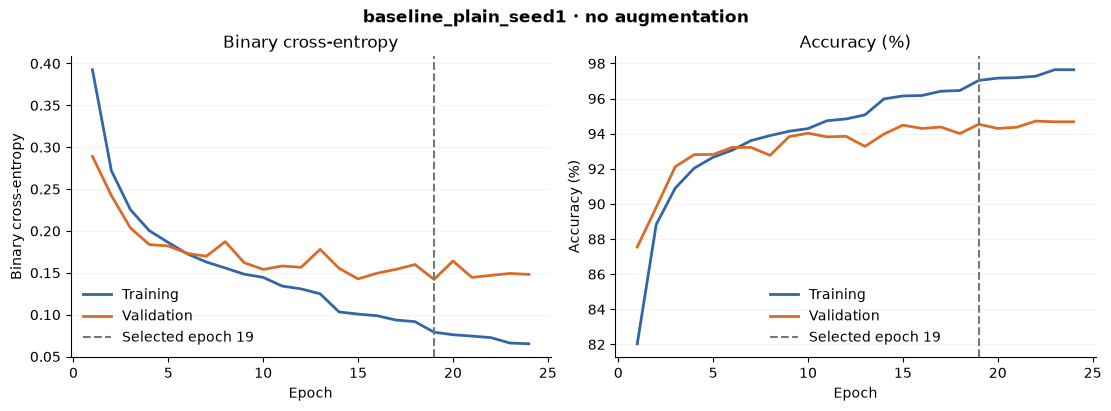

In [25]:
learning_fig = None
if history:
    epochs = [int(row["epoch"]) for row in history]
    learning_fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for ax, metric, scale, title in zip(axes, ["loss", "accuracy"], [1, 100], ["Binary cross-entropy", "Accuracy (%)"]):
        ax.plot(epochs, [float(row[f"train_{metric}"])*scale for row in history], label="Training", color="#3465a4", lw=2)
        ax.plot(epochs, [float(row[f"val_{metric}"])*scale for row in history], label="Validation", color="#d96b27", lw=2)
        ax.axvline(selected_epoch, color="#777777", ls="--", label=f"Selected epoch {selected_epoch}")
        ax.set(xlabel="Epoch", ylabel=title, title=title)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.15)
        ax.legend(frameon=False)
    learning_fig.suptitle(f"{RUN_NAME} · no augmentation", fontweight="bold")
    plt.show()
else:
    print("Training history will appear after this run completes.")

## 9. Load the selected model for analysis

For the completed baseline, the trained weights are included **inside this notebook** and can be loaded on a CPU. No retraining, dataset download, sibling `.py` file, or separate model file is required. If a local full run is present, its selected `best.pt` is used. New named runs use their own selected checkpoints; they never silently fall back to the bundled baseline.

The loaded `model` is ready for later analysis. Inputs must be `[batch, 3, 32, 32]` RGB float tensors scaled to `[0,1]` on `device`. `torch.sigmoid(model(inputs))` gives P(REAL). Full optimizer and recovery states stay in local training checkpoints; the bundled weights are for inference.

In [26]:
checkpoint = None
model = None
checkpoint_path = RUN_DIR / "best.pt"
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    checkpoint_source = checkpoint_path.relative_to(ROOT).as_posix()
elif MODEL_PATH.exists():
    exported_summary = read_json(RESULTS_DIR / "summary.json")
    assert file_sha256(MODEL_PATH) == exported_summary["model_sha256"]
    checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
    checkpoint_source = MODEL_PATH.relative_to(ROOT).as_posix()
elif RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
    raw_weights = embedded_bytes(f"models/{EMBEDDED_RUN}.pt")
    assert hashlib.sha256(raw_weights).hexdigest() == read_result("summary.json")["model_sha256"]
    checkpoint = torch.load(BytesIO(raw_weights), map_location="cpu", weights_only=True)
    checkpoint_source = "the weights bundled inside this notebook"

if checkpoint is not None:
    model = BaselineCNN().to(device)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    assert checkpoint["epoch"] == selected_epoch
    print(f"Loaded epoch {checkpoint['epoch']} from {checkpoint_source}")
    print("Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.")
else:
    print("No selected checkpoint exists for this named run. Finish training first.")

Loaded epoch 19 from the weights bundled inside this notebook
Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.


## 10. Inspect a few validation predictions

The learning curves summarize many images, so we'll also look at a few individual predictions to see what those results mean in practice. We'll select four real and four fake images from the validation split with a fixed random seed and pass them through the selected model. Each thumbnail will show its true label, predicted label, and the model's probability score for FAKE. Comparing these lets us spot both mistakes and cases where the model is uncertain, as well as confident mistakes that may be worth investigating later. The thumbnails are enlarged without smoothing for display, while the model still receives the original 32×32 images. These examples come from validation, not the test set, and eight images cannot represent the full error pattern.

This optional cell needs the locally prepared validation data. Without it, the notebook still loads the trained model and displays the other saved results.

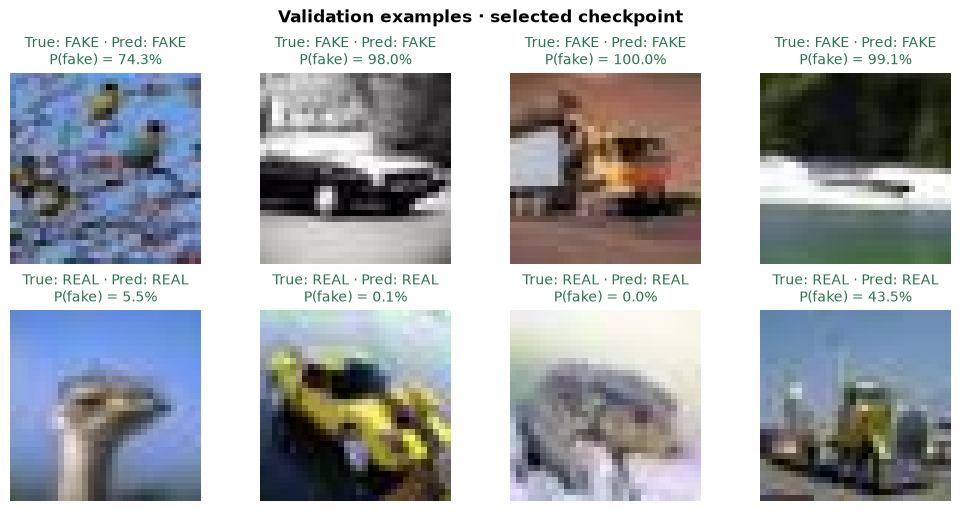

In [27]:
if model is not None and (DATA_DIR / "val_images.npy").exists():
    expected_manifest = checkpoint.get("manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256"))
    assert file_sha256(DATA_DIR / "manifest.csv") == expected_manifest
    val_images, val_labels, val_rows = load_split(DATA_DIR, "val")
    sample_rng = np.random.default_rng(42)
    sample_indices = np.concatenate([
        sample_rng.choice(np.flatnonzero(val_labels == label), size=4, replace=False)
        for label in (0, 1)
    ])
    inputs = torch.from_numpy(val_images[sample_indices]).to(device=device, dtype=torch.float32) / 255
    with torch.inference_mode():
        p_fake = (1 - torch.sigmoid(model(inputs))).cpu().numpy()
    fig, axes = plt.subplots(2, 4, figsize=(10, 5), layout="constrained")
    for ax, index, probability in zip(axes.flat, sample_indices, p_fake):
        truth = "FAKE" if val_labels[index] == 0 else "REAL"
        predicted = "FAKE" if probability > 0.5 else "REAL"
        ax.imshow(val_images[index].transpose(1, 2, 0), interpolation="nearest")
        ax.set_title(f"True: {truth} · Pred: {predicted}\nP(fake) = {probability:.1%}",
                     fontsize=10, color="#28734e" if truth == predicted else "#a63434")
        ax.axis("off")
    fig.suptitle("Validation examples · selected checkpoint", fontweight="bold")
    plt.show()
    del val_images, val_labels, val_rows, inputs
else:
    print("Validation preview skipped: a trained model and local validation cache are required.")

## 11. Final test evaluation

The threshold is fixed at 0.5. Enable `EVALUATE_TEST` only after training and model selection are complete. If test results already exist, this notebook reads them instead of evaluating again. Test metrics are not used to select the checkpoint or change hyperparameters.

Both the official 20,000-image test set and its 19,962 unique images are reported. In `review` mode the following numbers come from the saved evaluation; they are not a newly computed test score.

The table below will put validation, the full official test set, and the test set with repeated copies counted only once side by side. Alongside accuracy, we'll compare loss, ROC-AUC, the proportion of fake images detected, and the proportion of real images incorrectly flagged as fake. The last two columns are especially useful for understanding what an error means for each class. Comparing the two test rows also lets us see how much repeated images affect the reported scores, without selecting a model or threshold based on those results.

In [28]:
test_report = read_result("test_metrics.json")
if EVALUATE_TEST and test_report is None:
    evaluate_model(RUN_DIR, data_dir=DATA_DIR, device=DEVICE)
    test_report = read_result("test_metrics.json")
elif EVALUATE_TEST:
    print("Existing test evaluation found; reusing it.")

if test_report:
    rows = []
    for label, metrics in (("Validation", run_summary["validation"]),
                           ("Official test", test_report["official_test"]),
                           ("Unique test", test_report["unique_test"])):
        rows.append([label, f"{metrics['n']:,}", f"{metrics['accuracy']:.2%}",
                     f"{metrics['loss']:.4f}", f"{metrics['roc_auc_fake']:.4f}",
                     f"{metrics['fake_detection_rate']:.2%}", f"{metrics['real_flagged_fake_rate']:.2%}"])
    show_table(["Split", "Images", "Accuracy", "BCE", "ROC-AUC (fake)", "Fake detected", "Real flagged fake"], rows)
    print("Selected epoch:", test_report["selected_epoch"])
else:
    print("No test evaluation for this run. Finish model selection before enabling EVALUATE_TEST.")

| Split | Images | Accuracy | BCE | ROC-AUC (fake) | Fake detected | Real flagged fake |
| --- | --- | --- | --- | --- | --- | --- |
| Validation | 10,000 | 94.54% | 0.1421 | 0.9882 | 94.60% | 5.52% |
| Official test | 20,000 | 94.29% | 0.1501 | 0.9871 | 94.18% | 5.60% |
| Unique test | 19,962 | 94.29% | 0.1500 | 0.9871 | 94.19% | 5.60% |

Selected epoch: 19


### Where the test errors occur

Overall accuracy combines two different kinds of mistake: accepting a fake image as real and flagging a real image as fake. We'll separate them with a confusion matrix using the saved official-test counts from the fixed 0.5 threshold. Rows show the true labels and columns show the predicted labels, so the diagonal cells contain correct classifications. The top-right cell counts fake images that passed as real, and the bottom-left cell counts real images incorrectly flagged as fake. The printed numbers are image counts, with darker shading representing larger counts. Reading the off-diagonal cells will help us see which type of error is more common in this balanced test set. This displays the existing evaluation; it does not run a new test or change the threshold.

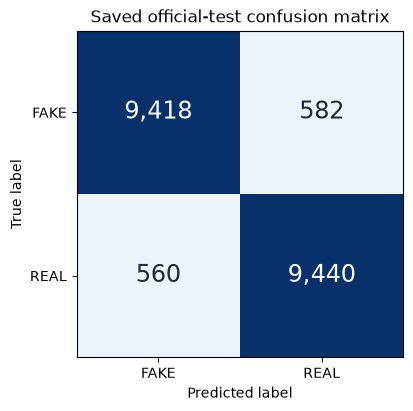

In [29]:
if test_report:
    cm = np.asarray(test_report["official_test"]["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    for (row, col), value in np.ndenumerate(cm):
        ax.text(col, row, f"{value:,}", ha="center", va="center", fontsize=17,
                color="white" if value > cm.max()/2 else "#1f2937")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["FAKE", "REAL"], yticklabels=["FAKE", "REAL"],
           xlabel="Predicted label", ylabel="True label", title="Saved official-test confusion matrix")
    plt.show()

## 12. Share one notebook; keep recovery checkpoints locally

**Only this `.ipynb` needs to be committed or downloaded for the completed baseline.** It includes the implementation, selected model weights, numerical results, and static figures. A teammate installs the packages, leaves `MODE = "review"`, and runs the notebook. Saved outputs can be read on GitHub without running anything. The interactive explorer requires the locally prepared training data and a live kernel.

New training still saves `best.pt`, `last.pt`, and one full checkpoint per epoch under `runs/<RUN_NAME>/`. A notebook alone cannot resume an interrupted run without that run's optimizer and random-state checkpoints. If needed, enable `EXPORT_RUN` below to create a **local** archive of a completed, evaluated run for team storage. This does not publish or commit files. The bundled baseline remains fixed when you train another named run.

Dataset downloads, caches, optional exported figures, and checkpoints are runtime files, not additional required repository files. Commit only the notebook for this workflow.

In [30]:
if EXPORT_RUN:
    if not (RUN_DIR / "test_metrics.json").exists():
        raise RuntimeError("A completed, evaluated local run is required for a full recovery archive.")
    archive_path = ROOT / "artifacts" / f"{RUN_NAME}.tar.gz"
    if archive_path.exists():
        print("Keeping the existing archive:", archive_path.relative_to(ROOT))
    else:
        archive_path.parent.mkdir(parents=True, exist_ok=True)
        temporary_archive = archive_path.with_suffix(".tmp")
        with tarfile.open(temporary_archive, "w:gz") as handle:
            handle.add(RUN_DIR, arcname=RUN_NAME)
        temporary_archive.replace(archive_path)
        archive_path.with_suffix(archive_path.suffix + ".sha256").write_text(
            f"{file_sha256(archive_path)}  {archive_path.name}\n")
        print("Saved local recovery archive:", archive_path.relative_to(ROOT))
else:
    print("Single-file sharing: copy or commit this notebook. The baseline weights and results are already bundled.")
print("Full recovery checkpoints are generated locally only when training is enabled.")

Single-file sharing: copy or commit this notebook. The baseline weights and results are already bundled.
Full recovery checkpoints are generated locally only when training is enabled.


## 13. What this baseline establishes

This is one seeded run on clean CIFAKE. It establishes a model and fixed split for the visualization project; it does not establish robustness to edits or detection of newer generators.

Next, develop transformation probes on validation images: JPEG quality, blur, resizing, and noise. Keep labels and image identities fixed while examining changes in confidence and predictions. After the probe settings are fixed, report a test evaluation. For a later augmentation comparison, reuse the same split and evaluation protocol and train a separately named model.

A failure under a transformation is evidence of sensitivity. It does not, by itself, prove shortcut learning; internal analysis and controlled comparisons belong in the later investigation.

**Implementation checks:** numerical feature checks and spectrum normalization run in the EDA section. The consolidated notebook was also checked in an otherwise empty directory, and its training/resume behavior was verified with a small synthetic dataset. The baseline model bytes, split manifest, and saved test results were preserved.